# Singh metaclone spatial atlas

## Scope and methods

This is a visual expansion of the frozen resolved-family registry, not new scientific testing. Each retained metaclone receives one separate map for shared WT Day 7 and for WT, Npm1c, and Dnmt3a at Days 14 and 27. The full original embedding provides the common gray context; no UMAP refit or expression-matrix access is performed.

Each snapshot is cell-weighted. A fixed Gaussian kernel and grid estimate probability density within that snapshot; the common color scale is identical across all density maps. Density indicates spatial concentration, not clone expansion, cell recovery, or independent replication. Sparse snapshots are shown as fixed navy raw points, without density encoding. Empty selections retain the gray background and zero counts, which do not establish extinction. HSPCs remain pooled.

All source-independent display choices are fixed before plotting: Gaussian bandwidth 0.4 original UMAP coordinate units per axis, a 256-by-256 computational grid extending four bandwidths beyond the full embedding, and common plot limits equal to fullmap extrema plus 0.4. Density requires at least 20 cells and three resolved families. Every map has its own full calculation, construction, SVG/PNG export and display cell. Gray fullmap points alone are rasterized in SVG; foreground points and text remain editable vector objects. The separate scale key defines density for all panels.

## Environment

Use the existing **chronoclone** environment, installed at `/path/to/ChronoClone/.runtime/chronoclone`; existing Conda-managed installation (no installation or mutation here), Jupyter kernel **chronoclone**. Exact Python/package versions and execution command are printed below. The builder is `build_atlas_notebook.py` in this directory; it generates explicit editable plot cells.


In [1]:

from pathlib import Path
import sys,platform,json,hashlib,datetime,warnings
import numpy as np
import pandas as pd
import h5py,scipy,matplotlib
from scipy.ndimage import gaussian_filter,map_coordinates
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display
from PIL import Image
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/singh/singh_landscape_expansion_20260911/atlas'
ENV=Path('/path/to/ChronoClone/.runtime/chronoclone')
assert Path(sys.executable).parent.parent==ENV
for directory in ['panels','tables','reports']:(OUT/directory).mkdir(parents=True,exist_ok=True)
execution_command=f'{ENV}/bin/python {ROOT}/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py {OUT}/0001_metaclone_spatial_atlas.ipynb'
environment={'name':'chronoclone','path':str(ENV),'manager':'existing Conda-managed environment; no mutation','kernel':'chronoclone',
             'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
             'h5py':h5py.__version__,'matplotlib':matplotlib.__version__,'execution_command':execution_command}
display(environment)
plt.rcParams.update({'font.family':'Arial','font.size':16,'axes.labelsize':16,'svg.fonttype':'none',
                     'savefig.facecolor':'white','figure.facecolor':'white','svg.hashsalt':'singh_atlas_20260911'})
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()
CELL_SOURCE=ROOT/'analysis_workspace/singh/singh_reference_response_20260911/dynamics/tables/cells_resolved.csv'
MAP_SOURCE=ROOT/'data/processed/singh_strack/adata_valid_keep_all.h5ad'
PALETTE_SOURCE=ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811/tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv'
source_manifest=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in [CELL_SOURCE,MAP_SOURCE,PALETTE_SOURCE]])
source_manifest.to_csv(OUT/'tables/source_manifest.csv',index=False)
display(source_manifest)


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing Conda-managed environment; no mutation',
 'kernel': 'chronoclone',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'scipy': '1.17.1',
 'h5py': '3.16.0',
 'matplotlib': '3.11.0',
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/0001_metaclone_spatial_atlas.ipynb'}

,source,bytes,sha256
0,analysis_workspace/singh/singh_reference_response_2...,3949086,1c6107fb429938c2c0ecdf2ef0119a606c3df10caea1c5...
1,data/processed/singh_strack/adata_valid_keep_a...,2859494374,9822997506ef9b2294c6c467cdb0fb6022c7a0c0e132f3...
2,analysis_workspace/singh/figure3_original_singh_lan...,3430,df1b27dc2c3440de24f4c345764d2da73a2bece5a461d9...


In [2]:

# Read only the cell registry, HDF5 observation index and stored embedding. Do not access X/raw/layers.
cells=pd.read_csv(CELL_SOURCE,keep_default_na=False)
assert cells.cell_id.is_unique and cells.clone.ne('').all() and cells.clone_resolved.eq(True).all()
with h5py.File(MAP_SOURCE,'r') as source:
    index_key=source['obs'].attrs['_index']
    if isinstance(index_key,bytes):index_key=index_key.decode()
    full_ids=pd.Index(source['obs'][index_key].asstr()[:],name='cell_id')
    full_umap=np.asarray(source['obsm']['X_umap'][:,:2],dtype=np.float64)
assert full_ids.is_unique and len(full_ids)==96662 and full_umap.shape==(len(full_ids),2)
assert np.isfinite(full_umap).all()
positions=full_ids.get_indexer(cells.cell_id)
assert (positions>=0).all()
cells['umap1']=full_umap[positions,0];cells['umap2']=full_umap[positions,1]
assert np.array_equal(cells[['umap1','umap2']].to_numpy(),full_umap[positions])
MC_IDS=sorted(cells.mc.astype(int).unique().tolist())
assert len(MC_IDS)==17
SNAPSHOTS=[('WT','D7'),('WT','D14'),('WT','D27'),('Npm1c','D14'),('Npm1c','D27'),('Dnmt3a','D14'),('Dnmt3a','D27')]
assert set(zip(cells.arm,cells.day))==set(SNAPSHOTS)
assert cells.groupby('clone').mc.nunique().max()==1
assert not cells[['umap1','umap2']].isna().any().any()
cells[['cell_id','mc','arm','day','clone','umap1','umap2']].to_csv(OUT/'tables/atlas_cell_coordinates.csv.gz',index=False)
BANDWIDTH=0.4
GRID_SIZE=256
PLOT_XLIM=(full_umap[:,0].min()-0.4,full_umap[:,0].max()+0.4)
PLOT_YLIM=(full_umap[:,1].min()-0.4,full_umap[:,1].max()+0.4)
X_EDGES=np.linspace(full_umap[:,0].min()-4*BANDWIDTH,full_umap[:,0].max()+4*BANDWIDTH,GRID_SIZE+1)
Y_EDGES=np.linspace(full_umap[:,1].min()-4*BANDWIDTH,full_umap[:,1].max()+4*BANDWIDTH,GRID_SIZE+1)
DX=float(X_EDGES[1]-X_EDGES[0]);DY=float(Y_EDGES[1]-Y_EDGES[0])
X_CENTERS=(X_EDGES[:-1]+X_EDGES[1:])/2;Y_CENTERS=(Y_EDGES[:-1]+Y_EDGES[1:])/2
MIN_DENSITY_CELLS=20;MIN_DENSITY_FAMILIES=3
SPARSE_COLOR='#234B6C'
MC_LABEL_COLORS={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
assert set(MC_LABEL_COLORS)==set(MC_IDS)
palette_source=pd.read_csv(PALETTE_SOURCE)
assert dict(zip(palette_source.metaclone.astype(int),palette_source.label_color))==MC_LABEL_COLORS
display(palette_source[['metaclone','label_color']])
design={'fullmap_cells':len(full_ids),'registry_cells':len(cells),'unique_families':cells.clone.nunique(),
        'metaclones':MC_IDS,'snapshots':SNAPSHOTS,'expected_maps':len(MC_IDS)*len(SNAPSHOTS),
        'plot_xlim':PLOT_XLIM,'plot_ylim':PLOT_YLIM,'bandwidth_umap_units':BANDWIDTH,
        'grid_size':[GRID_SIZE,GRID_SIZE],'grid_dx':DX,'grid_dy':DY,
        'density_min_cells':MIN_DENSITY_CELLS,'density_min_families':MIN_DENSITY_FAMILIES,
        'density_weighting':'each observed cell equally weighted within its MC/arm/day snapshot',
        'source_coordinate_identity':'exact float64 values from original X_umap in source row order',
        'mc_label_palette':MC_LABEL_COLORS,'font_family':'Arial',
        'expression_matrix_accessed':False,'umap_refitted':False,'background_rasterized_only':True}
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(design)
display(cells.groupby(['arm','day']).agg(cells=('cell_id','size'),families=('clone','nunique')).reset_index())


,metaclone,label_color
0,0,#f77189
1,1,#f8763b
2,2,#d28e32
3,3,#b79932
4,4,#9ea231
5,5,#7caa31
6,6,#31b345
7,7,#34b081
8,9,#35ae9a
9,10,#36acad


{'fullmap_cells': 96662,
 'registry_cells': 14896,
 'unique_families': 1516,
 'metaclones': [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17, 19],
 'snapshots': [('WT', 'D7'),
  ('WT', 'D14'),
  ('WT', 'D27'),
  ('Npm1c', 'D14'),
  ('Npm1c', 'D27'),
  ('Dnmt3a', 'D14'),
  ('Dnmt3a', 'D27')],
 'expected_maps': 119,
 'plot_xlim': (np.float64(-5.9684041976928714), np.float64(7.454280757904053)),
 'plot_ylim': (np.float64(-9.033657455444336), np.float64(5.982400798797608)),
 'bandwidth_umap_units': 0.4,
 'grid_size': [256, 256],
 'grid_dx': 0.06180736310780066,
 'grid_dy': 0.06803147755563188,
 'density_min_cells': 20,
 'density_min_families': 3,
 'density_weighting': 'each observed cell equally weighted within its MC/arm/day snapshot',
 'source_coordinate_identity': 'exact float64 values from original X_umap in source row order',
 'mc_label_palette': {0: '#f77189',
  1: '#f8763b',
  2: '#d28e32',
  3: '#b79932',
  4: '#9ea231',
  5: '#7caa31',
  6: '#31b345',
  7: '#34b081',
  9: '#

,arm,day,cells,families
0,Dnmt3a,D14,1525,506
1,Dnmt3a,D27,1838,98
2,Npm1c,D14,828,280
3,Npm1c,D27,3543,68
4,WT,D14,3515,1512
5,WT,D27,934,138
6,WT,D7,2713,1514


In [3]:

# Shared scale calculation only: this creates no figure. Each map recomputes its own density inline below.
scale_rows=[]
for mc in MC_IDS:
    for arm,day in SNAPSHOTS:
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)]
        n=len(selected);families=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and families>=MIN_DENSITY_FAMILIES
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            peak=float(density.max());mass=float(density.sum()*DX*DY)
            assert np.isfinite(density).all() and abs(mass-1)<0.003
        else:peak=np.nan;mass=np.nan
        scale_rows.append({'mc':mc,'arm':arm,'day':day,'cells':n,'families':families,
                           'representation':'density_colored_points' if eligible else ('raw_points_sparse' if n else 'empty'),
                           'density_peak':peak,'density_integrated_mass':mass})
scale_table=pd.DataFrame(scale_rows)
assert len(scale_table)==119 and not scale_table[['mc','arm','day']].duplicated().any()
DENSITY_MAX=float(scale_table.density_peak.max())
assert np.isfinite(DENSITY_MAX) and DENSITY_MAX>0
DENSITY_NORM=Normalize(vmin=0,vmax=DENSITY_MAX,clip=False)
scale_table.to_csv(OUT/'tables/snapshot_support_and_density_scale.csv',index=False)
design['density_common_vmin']=0;design['density_common_vmax']=DENSITY_MAX
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(scale_table)
print('Common density color limits:',0,DENSITY_MAX)
print('Representation counts:',scale_table.representation.value_counts().to_dict())
render_records=[]


,mc,arm,day,cells,families,representation,density_peak,density_integrated_mass
0,0,WT,D7,935,596,density_colored_points,0.114309,1.0
1,0,WT,D14,1039,593,density_colored_points,0.068940,1.0
2,0,WT,D27,0,0,empty,NaN,NaN
3,0,Npm1c,D14,218,90,density_colored_points,0.055300,1.0
4,0,Npm1c,D27,589,26,density_colored_points,0.086206,1.0
...,...,...,...,...,...,...,...,...
114,19,WT,D27,99,14,density_colored_points,0.089719,1.0
115,19,Npm1c,D14,0,0,empty,NaN,NaN
116,19,Npm1c,D27,64,3,density_colored_points,0.094650,1.0
117,19,Dnmt3a,D14,4,3,raw_points_sparse,NaN,NaN


Common density color limits: 0 0.34375069516975765
Representation counts: {'density_colored_points': 72, 'empty': 24, 'raw_points_sparse': 23}


### MC0 · WT · Day 7

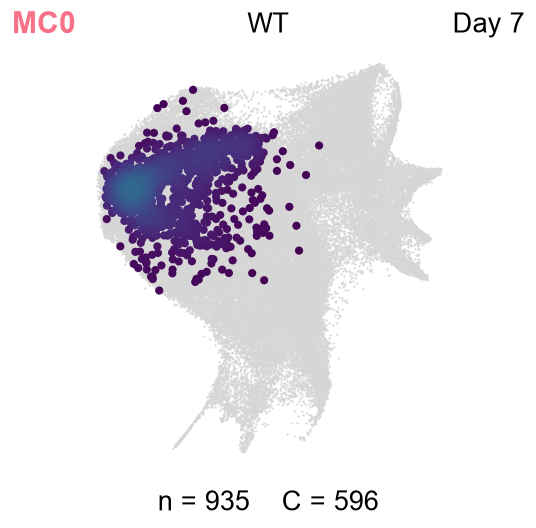

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d7.png


In [4]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='WT';day='D7';stem='mc00_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · WT · Day 14

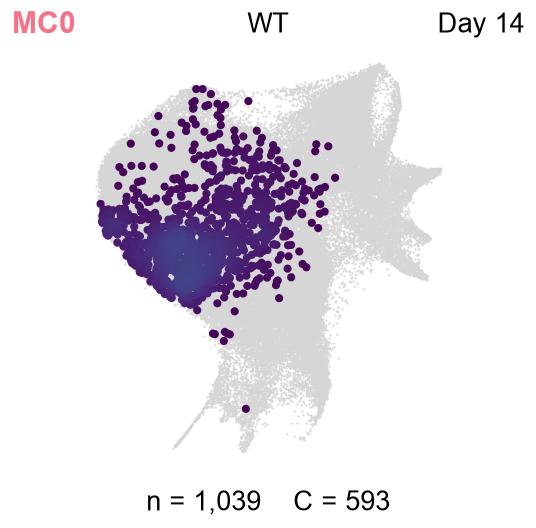

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d14.png


In [5]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='WT';day='D14';stem='mc00_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · WT · Day 27

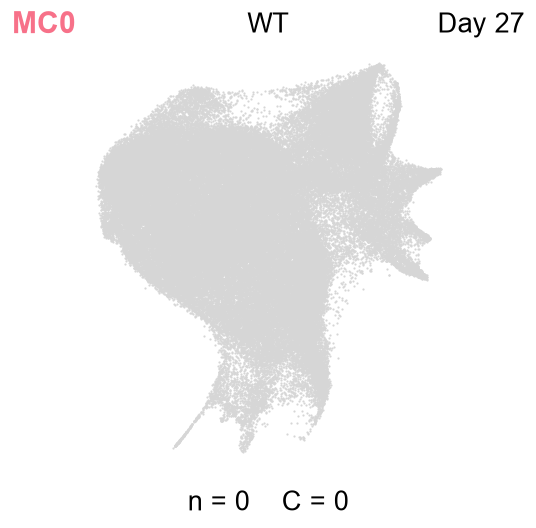

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_wt_d27.png


In [6]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='WT';day='D27';stem='mc00_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · Npm1c · Day 14

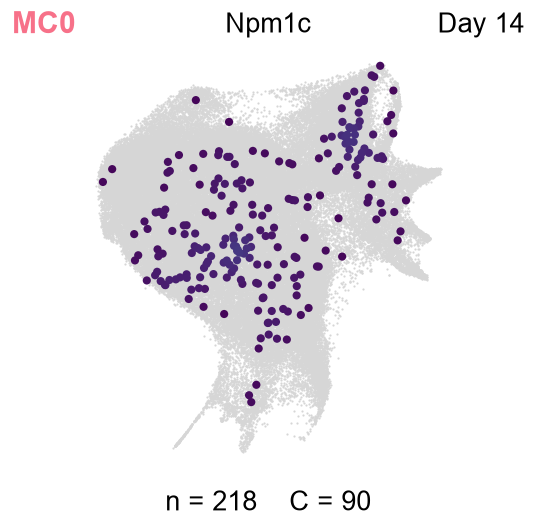

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_npm1c_d14.png


In [7]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='Npm1c';day='D14';stem='mc00_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · Npm1c · Day 27

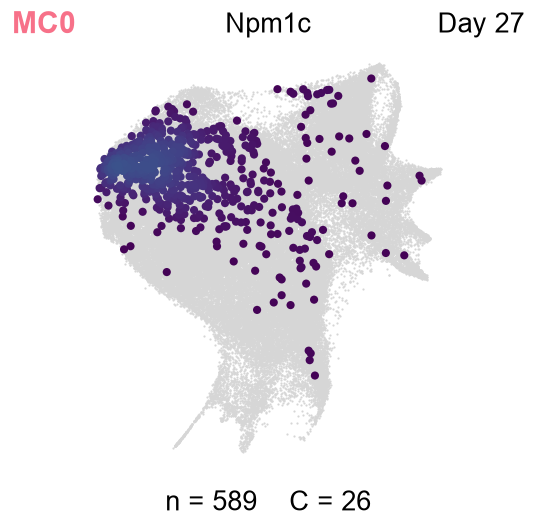

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_npm1c_d27.png


In [8]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='Npm1c';day='D27';stem='mc00_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · Dnmt3a · Day 14

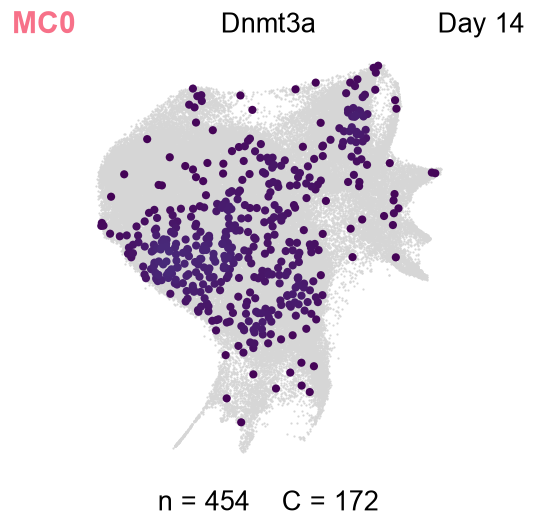

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_dnmt3a_d14.png


In [9]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='Dnmt3a';day='D14';stem='mc00_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC0 · Dnmt3a · Day 27

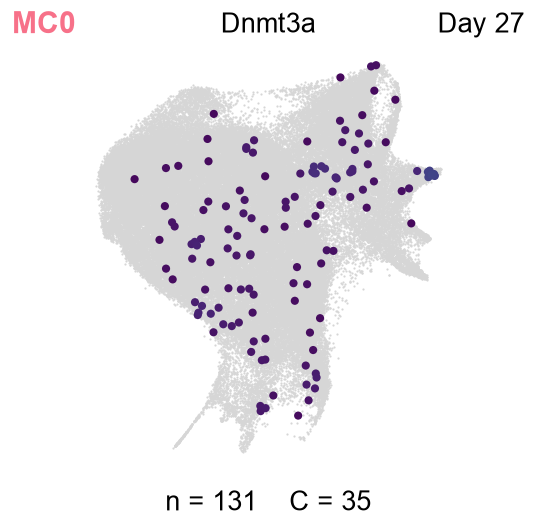

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc00_dnmt3a_d27.png


In [10]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=0;arm='Dnmt3a';day='D27';stem='mc00_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · WT · Day 7

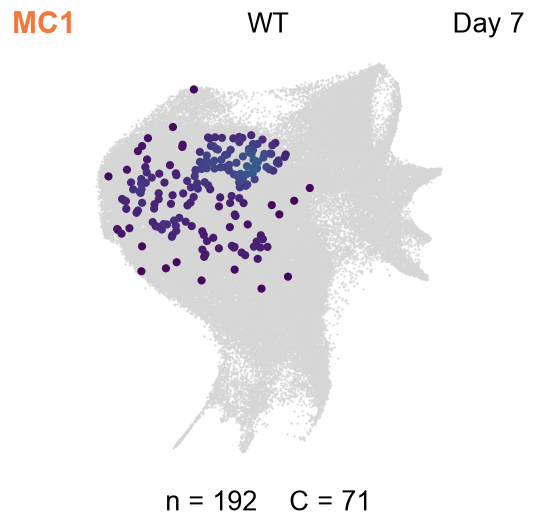

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d7.png


In [11]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='WT';day='D7';stem='mc01_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · WT · Day 14

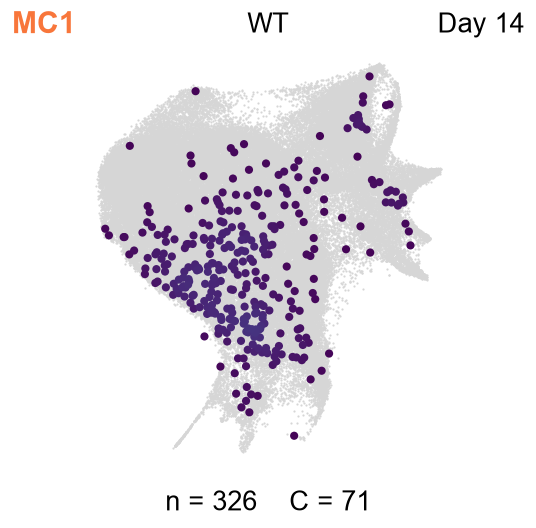

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d14.png


In [12]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='WT';day='D14';stem='mc01_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · WT · Day 27

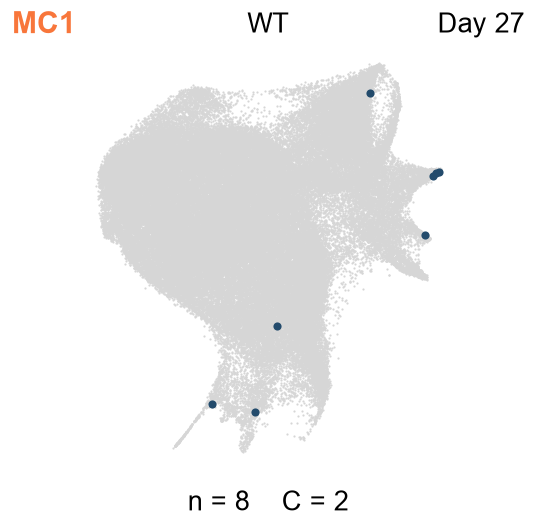

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_wt_d27.png


In [13]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='WT';day='D27';stem='mc01_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · Npm1c · Day 14

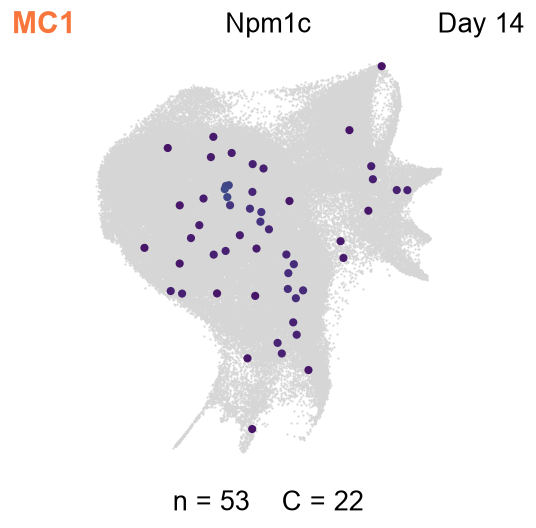

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_npm1c_d14.png


In [14]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='Npm1c';day='D14';stem='mc01_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · Npm1c · Day 27

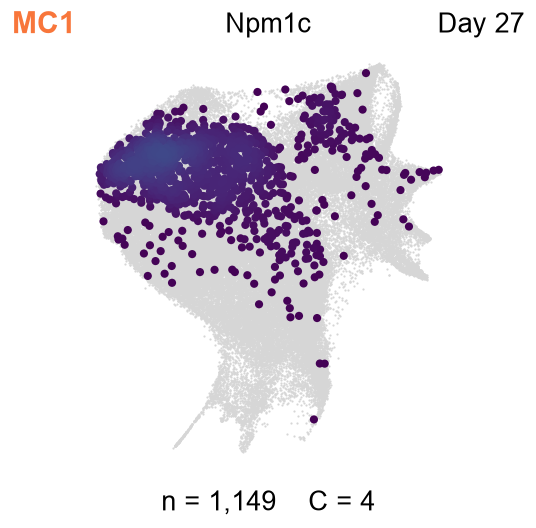

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_npm1c_d27.png


In [15]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='Npm1c';day='D27';stem='mc01_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · Dnmt3a · Day 14

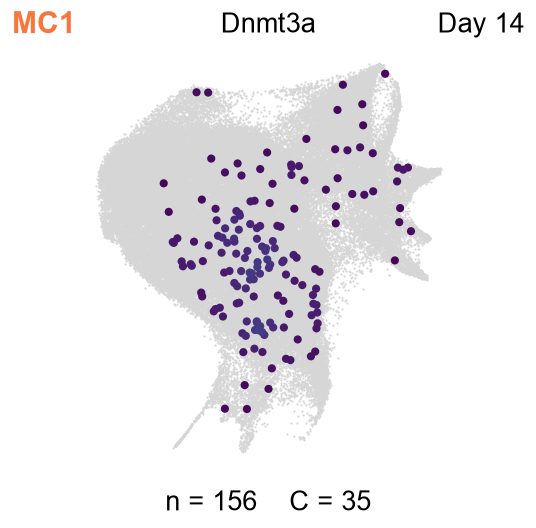

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_dnmt3a_d14.png


In [16]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='Dnmt3a';day='D14';stem='mc01_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC1 · Dnmt3a · Day 27

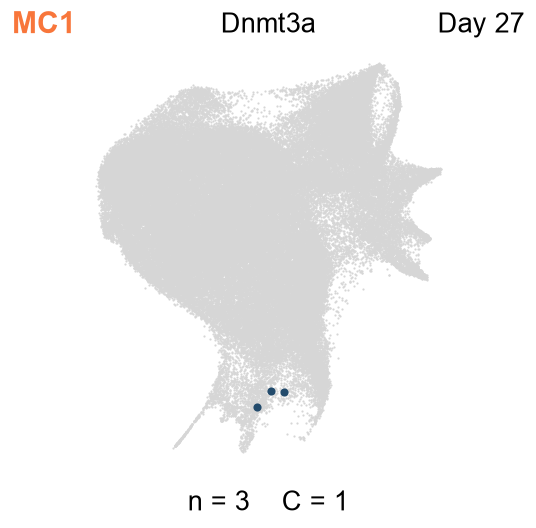

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc01_dnmt3a_d27.png


In [17]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=1;arm='Dnmt3a';day='D27';stem='mc01_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · WT · Day 7

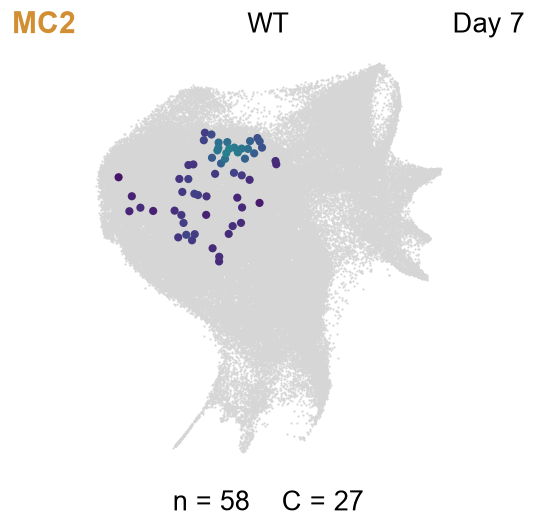

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d7.png


In [18]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='WT';day='D7';stem='mc02_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · WT · Day 14

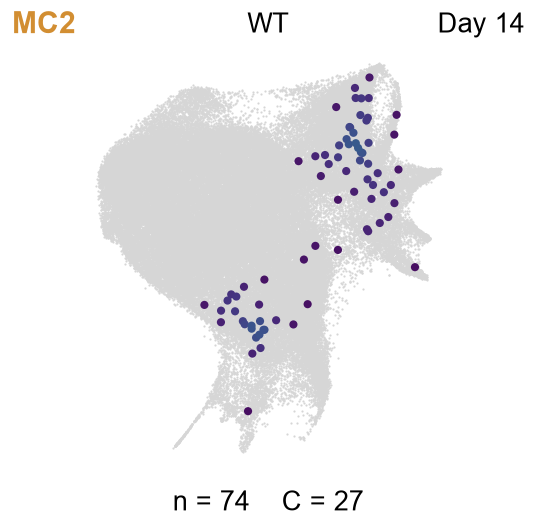

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d14.png


In [19]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='WT';day='D14';stem='mc02_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · WT · Day 27

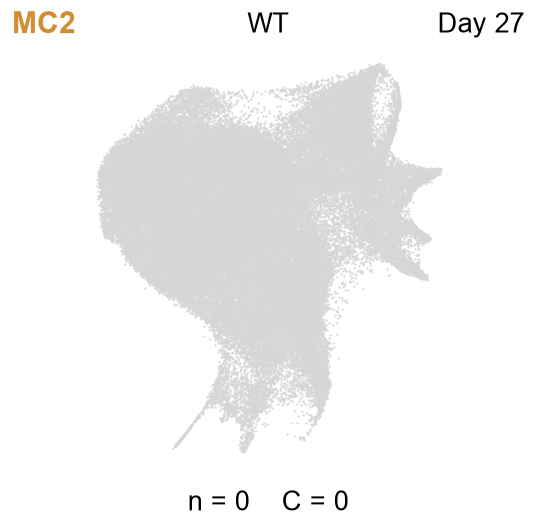

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_wt_d27.png


In [20]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='WT';day='D27';stem='mc02_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · Npm1c · Day 14

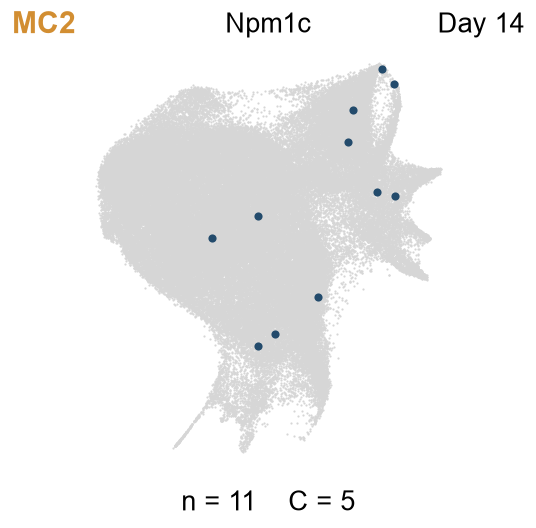

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_npm1c_d14.png


In [21]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='Npm1c';day='D14';stem='mc02_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · Npm1c · Day 27

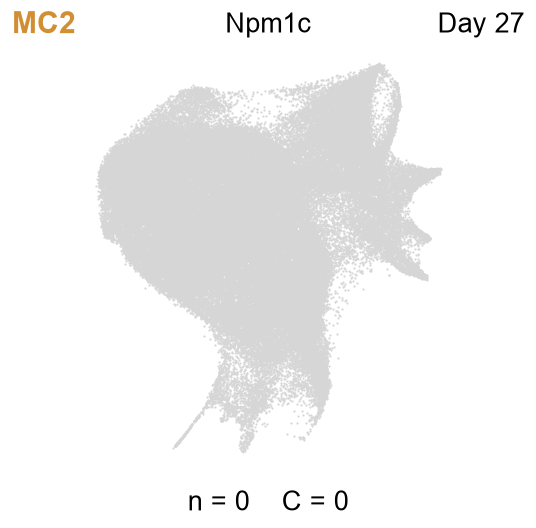

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_npm1c_d27.png


In [22]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='Npm1c';day='D27';stem='mc02_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · Dnmt3a · Day 14

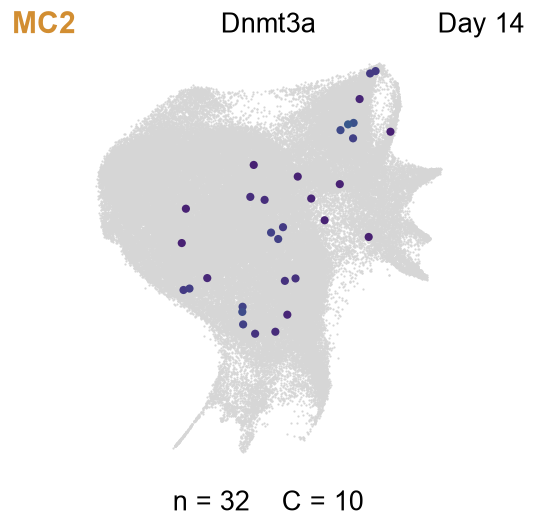

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_dnmt3a_d14.png


In [23]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='Dnmt3a';day='D14';stem='mc02_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC2 · Dnmt3a · Day 27

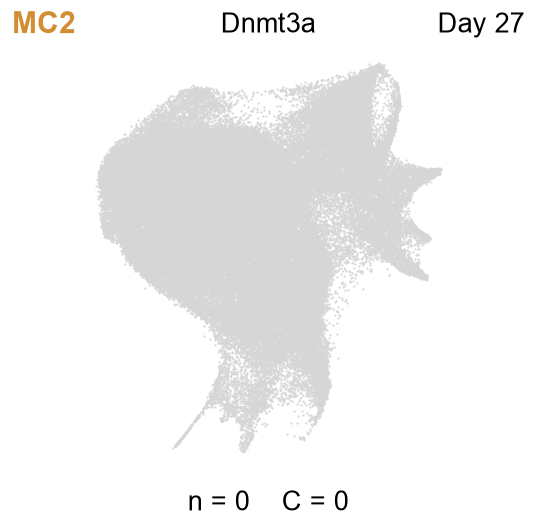

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc02_dnmt3a_d27.png


In [24]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=2;arm='Dnmt3a';day='D27';stem='mc02_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · WT · Day 7

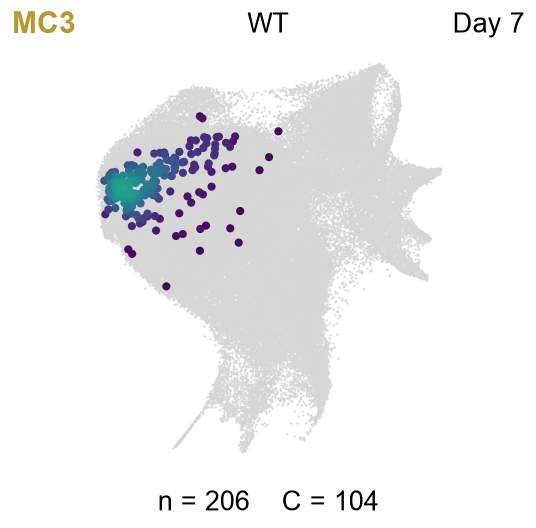

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d7.png


In [25]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='WT';day='D7';stem='mc03_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · WT · Day 14

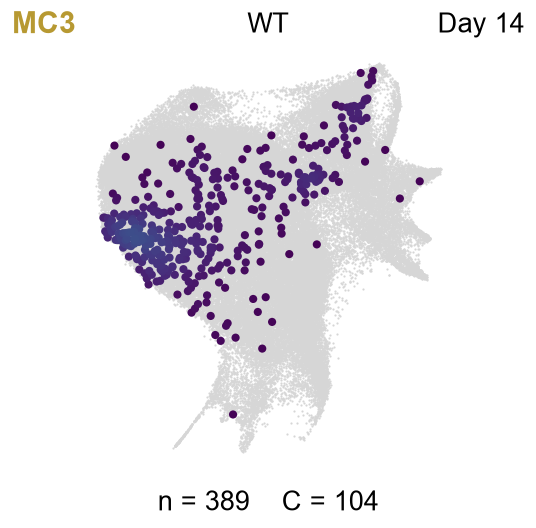

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d14.png


In [26]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='WT';day='D14';stem='mc03_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · WT · Day 27

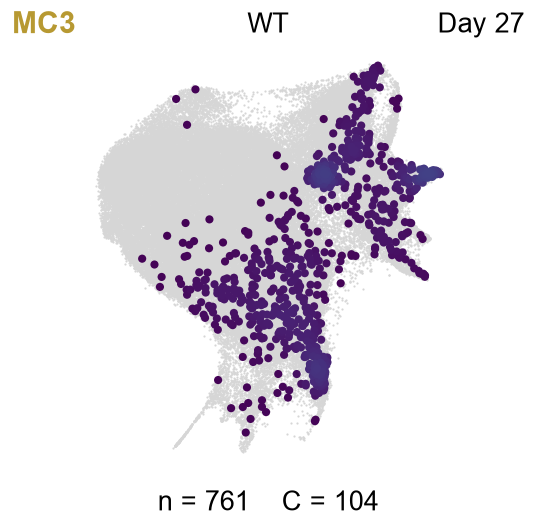

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_wt_d27.png


In [27]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='WT';day='D27';stem='mc03_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · Npm1c · Day 14

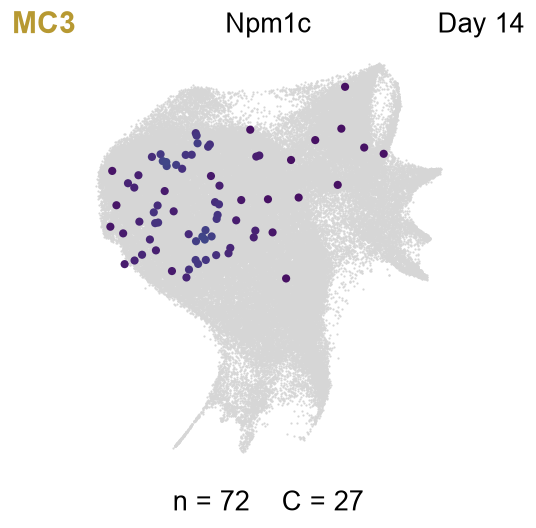

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_npm1c_d14.png


In [28]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='Npm1c';day='D14';stem='mc03_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · Npm1c · Day 27

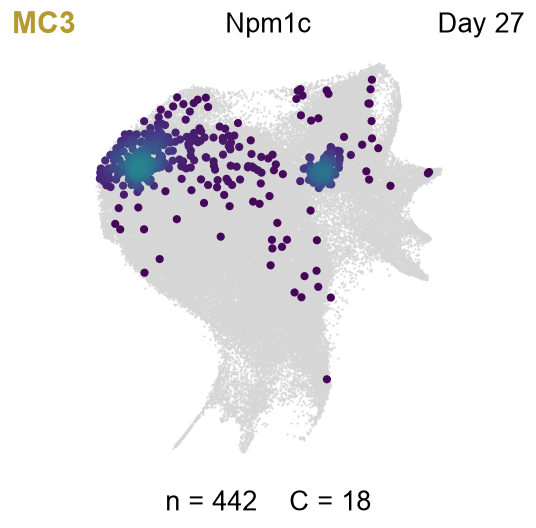

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_npm1c_d27.png


In [29]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='Npm1c';day='D27';stem='mc03_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · Dnmt3a · Day 14

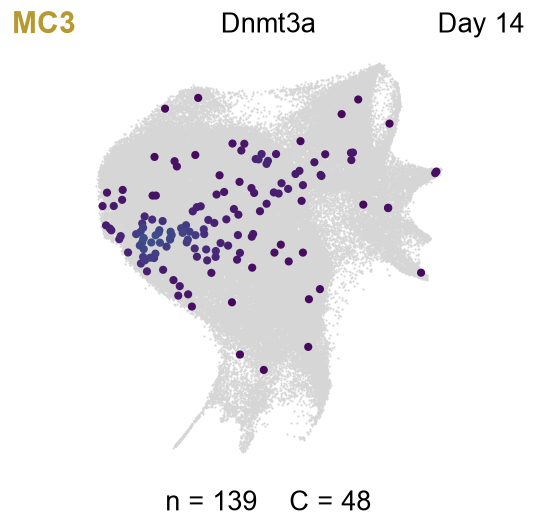

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_dnmt3a_d14.png


In [30]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='Dnmt3a';day='D14';stem='mc03_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC3 · Dnmt3a · Day 27

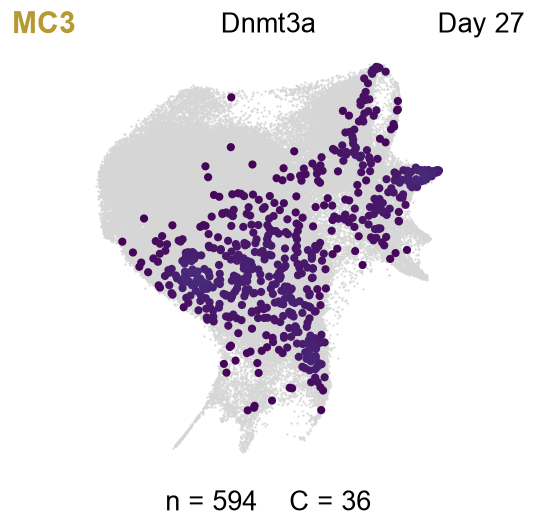

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc03_dnmt3a_d27.png


In [31]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=3;arm='Dnmt3a';day='D27';stem='mc03_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · WT · Day 7

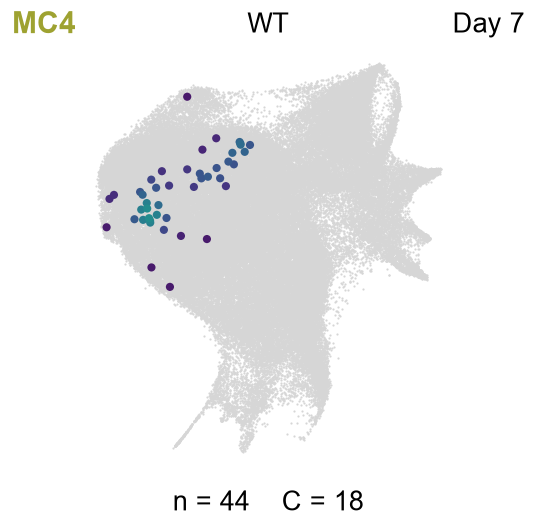

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d7.png


In [32]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='WT';day='D7';stem='mc04_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · WT · Day 14

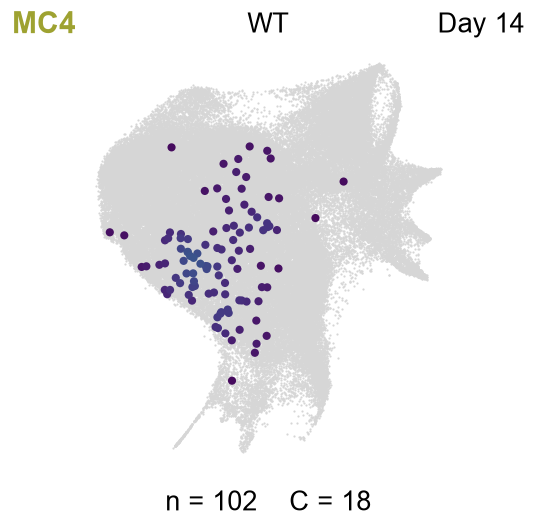

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d14.png


In [33]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='WT';day='D14';stem='mc04_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · WT · Day 27

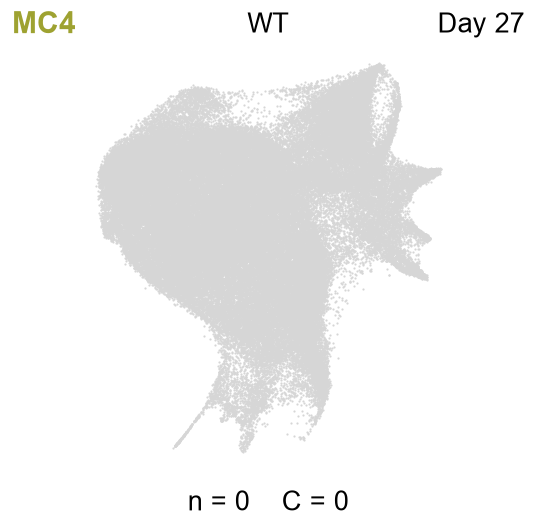

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_wt_d27.png


In [34]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='WT';day='D27';stem='mc04_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · Npm1c · Day 14

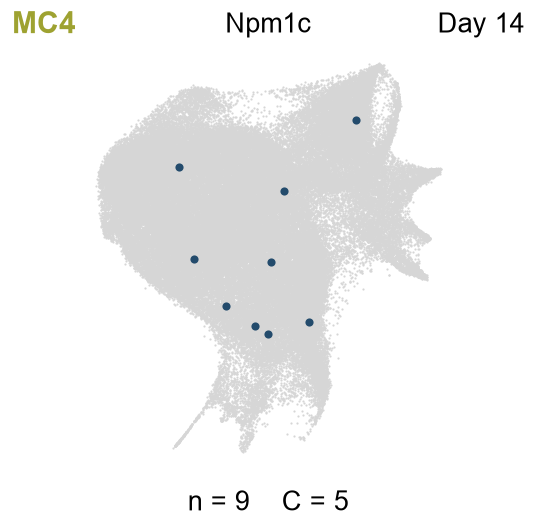

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_npm1c_d14.png


In [35]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='Npm1c';day='D14';stem='mc04_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · Npm1c · Day 27

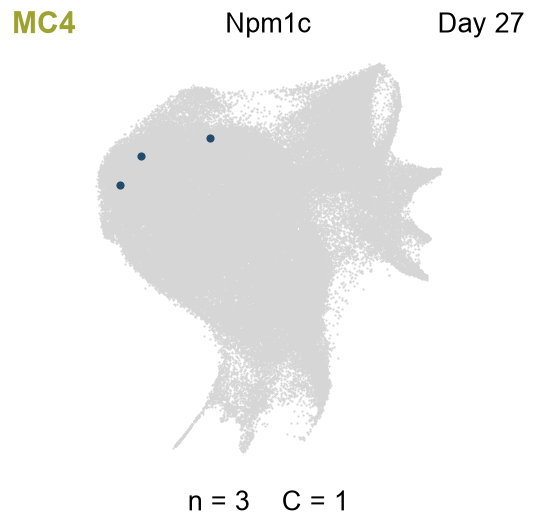

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_npm1c_d27.png


In [36]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='Npm1c';day='D27';stem='mc04_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · Dnmt3a · Day 14

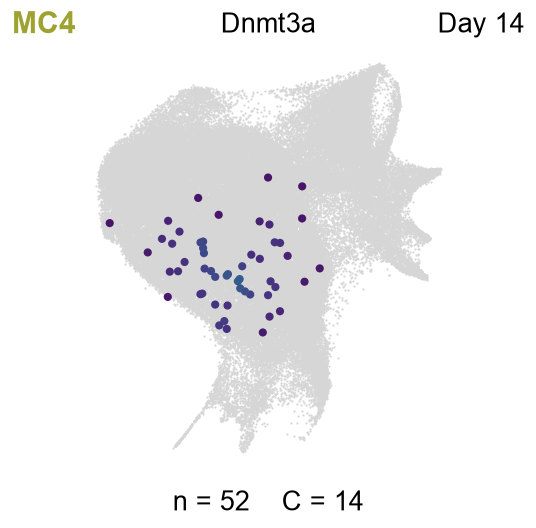

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_dnmt3a_d14.png


In [37]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='Dnmt3a';day='D14';stem='mc04_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC4 · Dnmt3a · Day 27

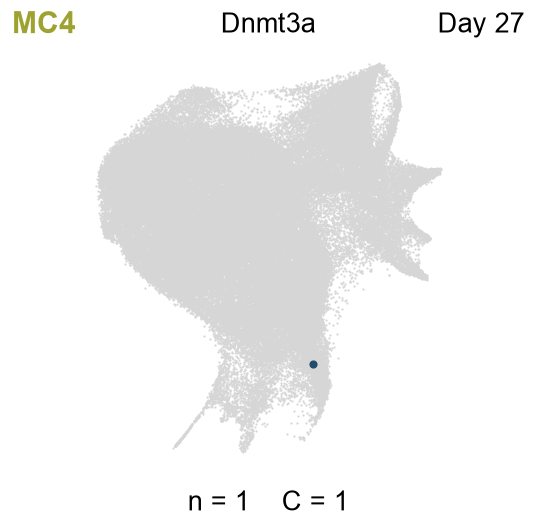

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc04_dnmt3a_d27.png


In [38]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=4;arm='Dnmt3a';day='D27';stem='mc04_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · WT · Day 7

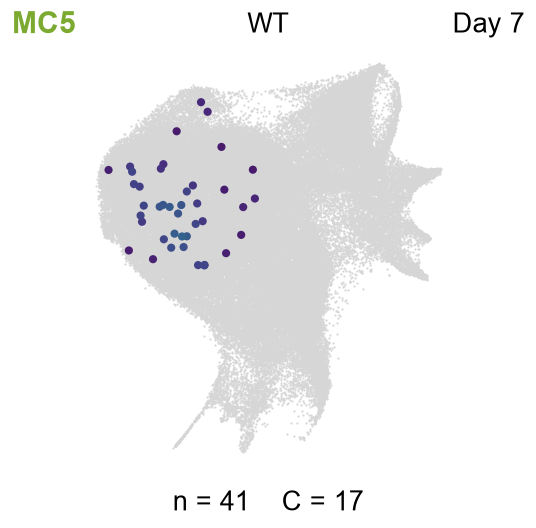

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d7.png


In [39]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='WT';day='D7';stem='mc05_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · WT · Day 14

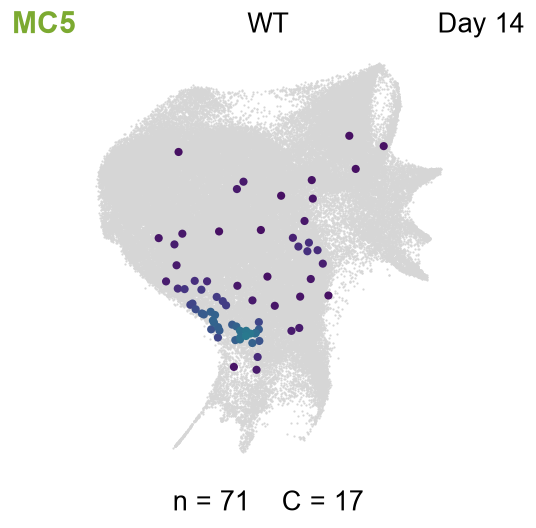

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d14.png


In [40]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='WT';day='D14';stem='mc05_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · WT · Day 27

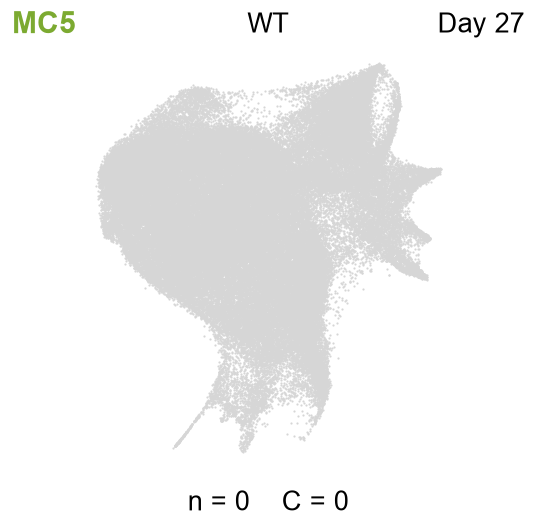

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_wt_d27.png


In [41]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='WT';day='D27';stem='mc05_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · Npm1c · Day 14

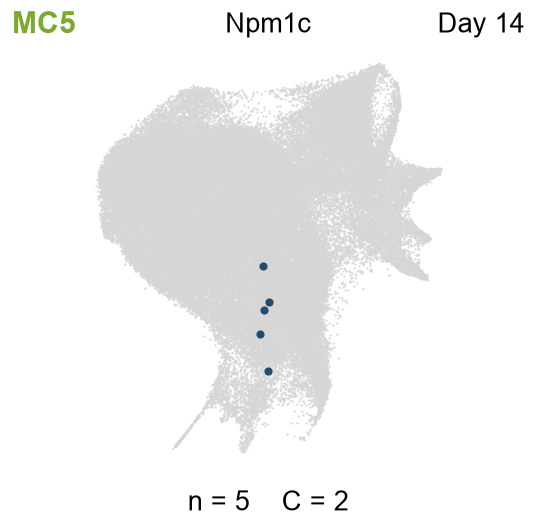

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_npm1c_d14.png


In [42]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='Npm1c';day='D14';stem='mc05_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · Npm1c · Day 27

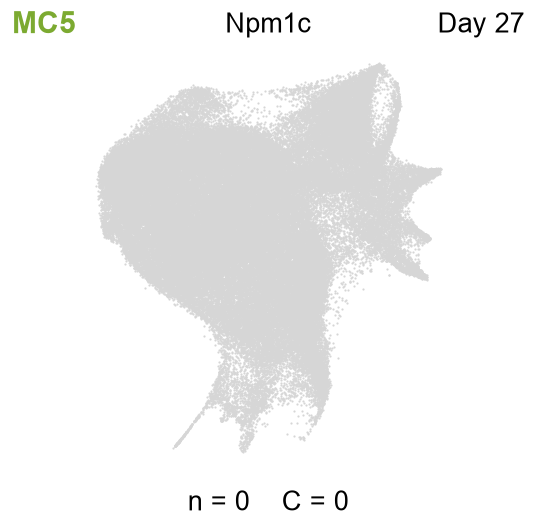

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_npm1c_d27.png


In [43]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='Npm1c';day='D27';stem='mc05_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · Dnmt3a · Day 14

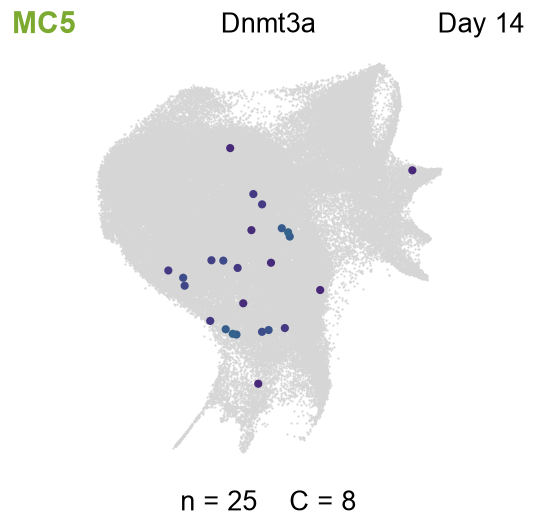

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_dnmt3a_d14.png


In [44]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='Dnmt3a';day='D14';stem='mc05_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC5 · Dnmt3a · Day 27

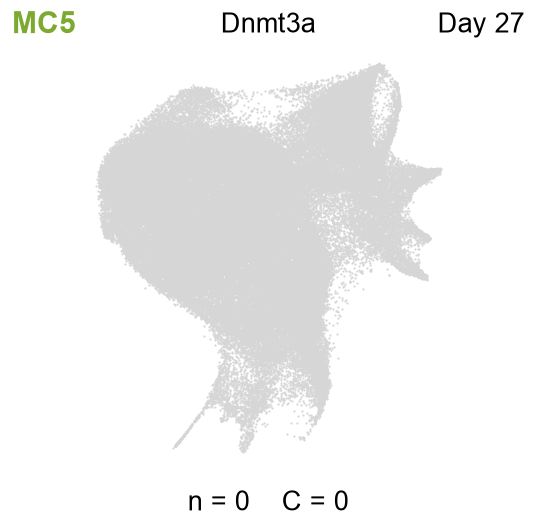

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc05_dnmt3a_d27.png


In [45]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=5;arm='Dnmt3a';day='D27';stem='mc05_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · WT · Day 7

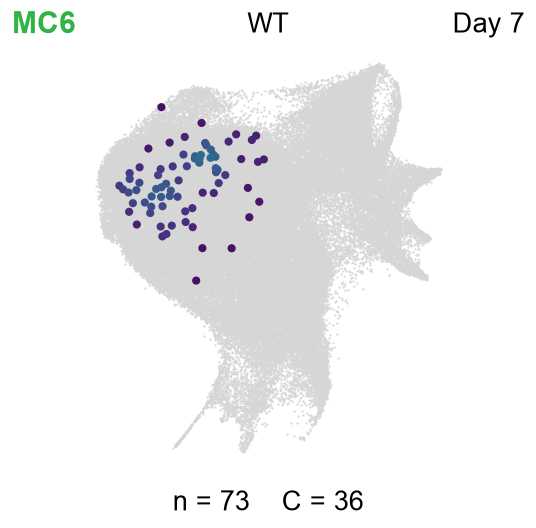

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d7.png


In [46]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='WT';day='D7';stem='mc06_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · WT · Day 14

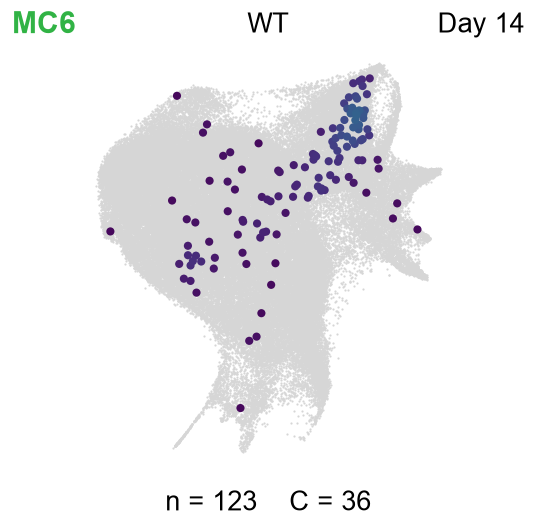

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d14.png


In [47]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='WT';day='D14';stem='mc06_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · WT · Day 27

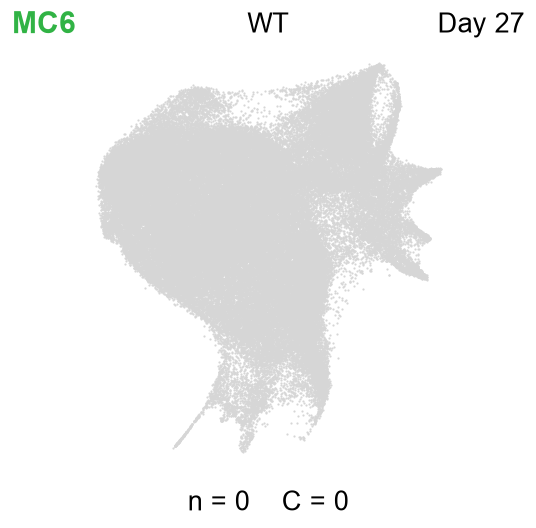

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_wt_d27.png


In [48]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='WT';day='D27';stem='mc06_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · Npm1c · Day 14

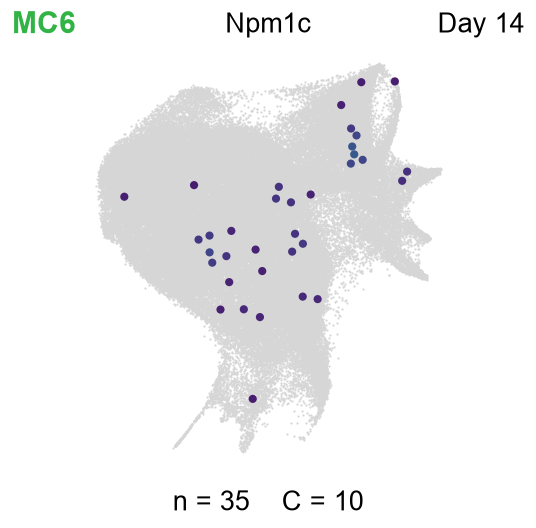

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_npm1c_d14.png


In [49]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='Npm1c';day='D14';stem='mc06_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · Npm1c · Day 27

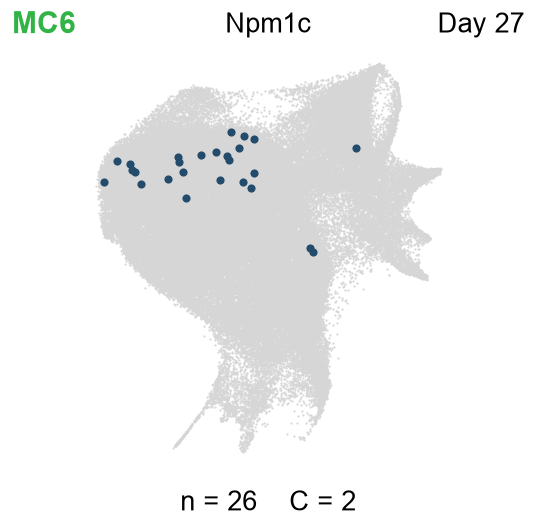

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_npm1c_d27.png


In [50]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='Npm1c';day='D27';stem='mc06_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · Dnmt3a · Day 14

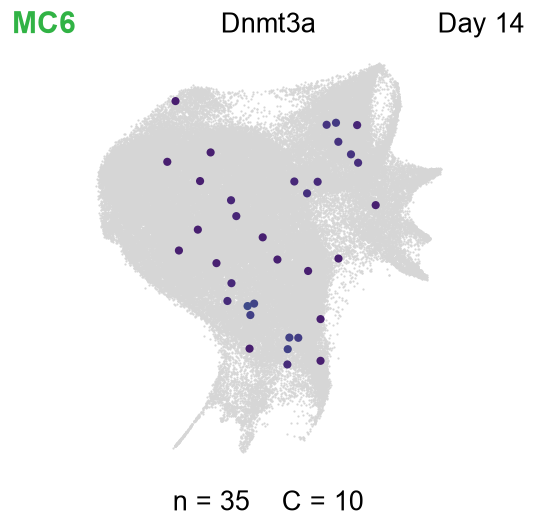

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_dnmt3a_d14.png


In [51]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='Dnmt3a';day='D14';stem='mc06_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC6 · Dnmt3a · Day 27

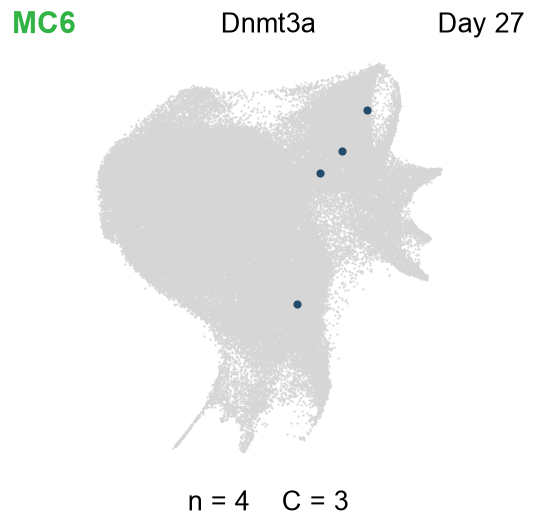

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc06_dnmt3a_d27.png


In [52]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=6;arm='Dnmt3a';day='D27';stem='mc06_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · WT · Day 7

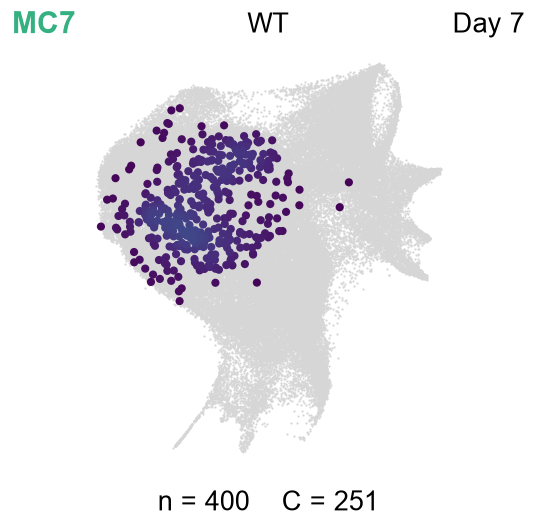

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d7.png


In [53]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='WT';day='D7';stem='mc07_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · WT · Day 14

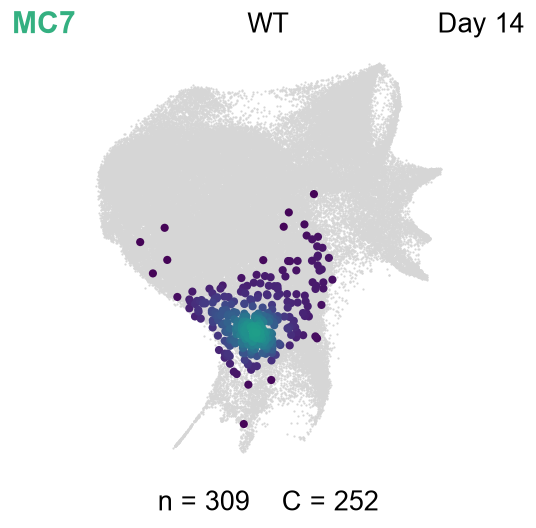

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d14.png


In [54]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='WT';day='D14';stem='mc07_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · WT · Day 27

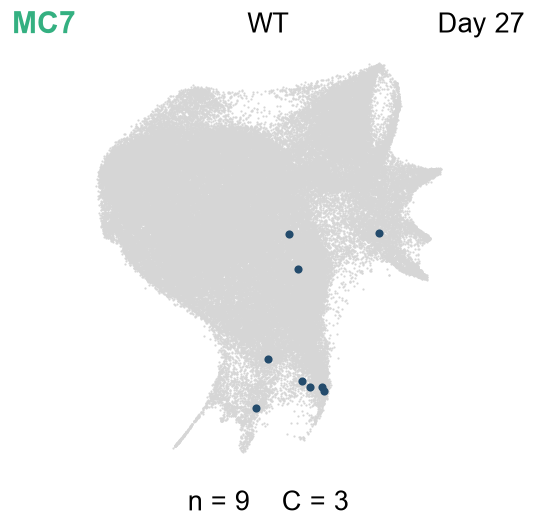

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_wt_d27.png


In [55]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='WT';day='D27';stem='mc07_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · Npm1c · Day 14

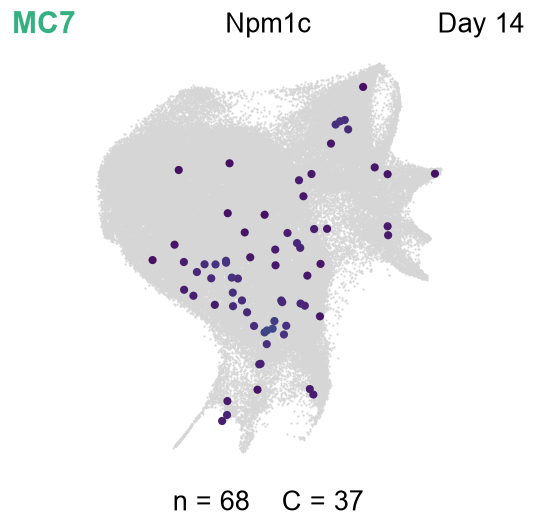

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_npm1c_d14.png


In [56]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='Npm1c';day='D14';stem='mc07_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · Npm1c · Day 27

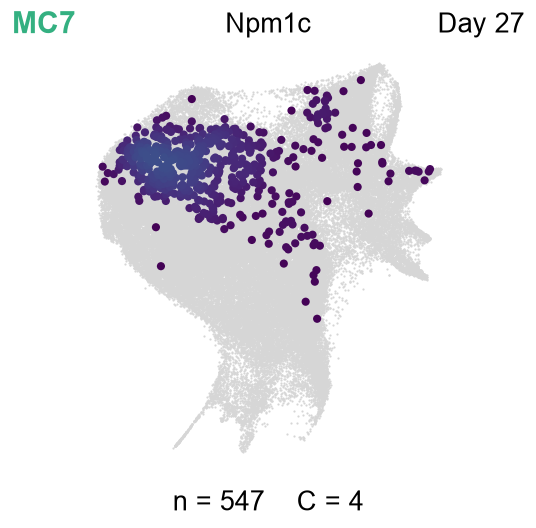

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_npm1c_d27.png


In [57]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='Npm1c';day='D27';stem='mc07_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · Dnmt3a · Day 14

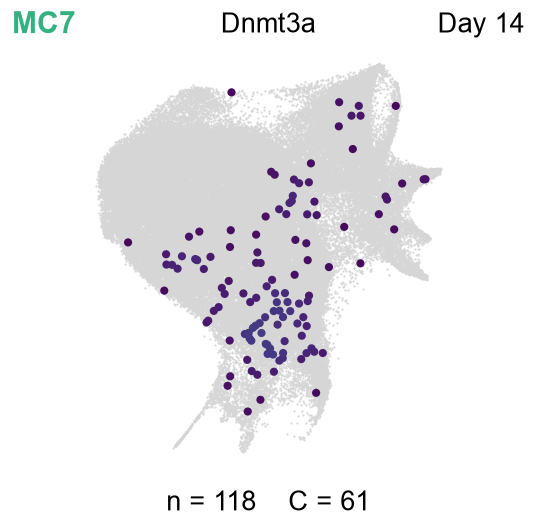

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_dnmt3a_d14.png


In [58]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='Dnmt3a';day='D14';stem='mc07_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC7 · Dnmt3a · Day 27

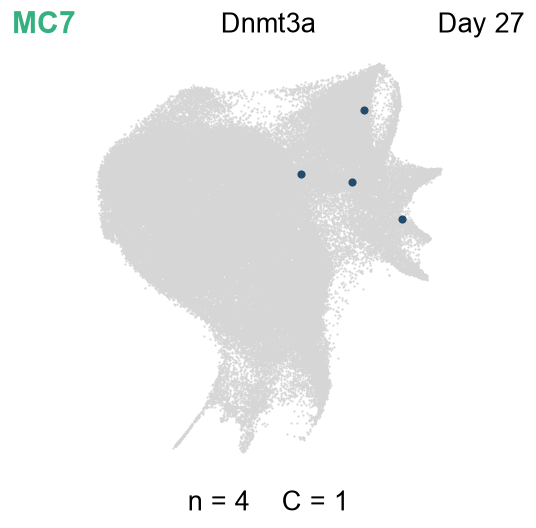

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc07_dnmt3a_d27.png


In [59]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=7;arm='Dnmt3a';day='D27';stem='mc07_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · WT · Day 7

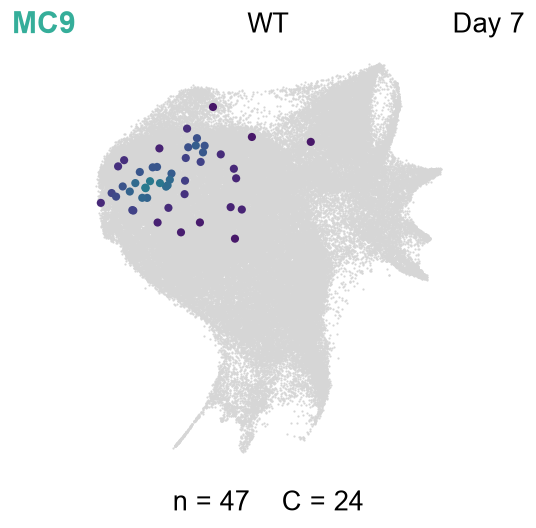

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d7.png


In [60]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='WT';day='D7';stem='mc09_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · WT · Day 14

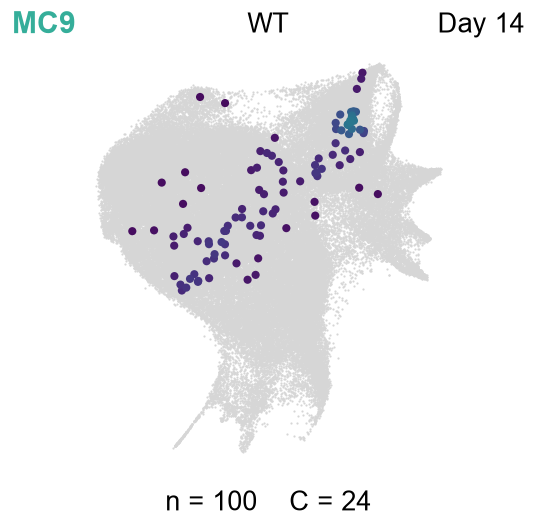

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d14.png


In [61]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='WT';day='D14';stem='mc09_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · WT · Day 27

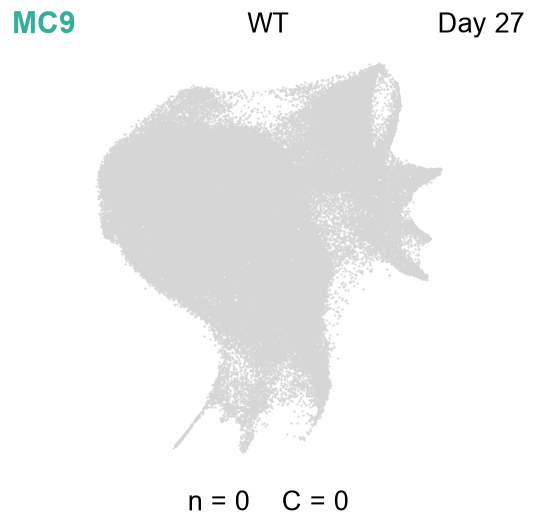

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_wt_d27.png


In [62]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='WT';day='D27';stem='mc09_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · Npm1c · Day 14

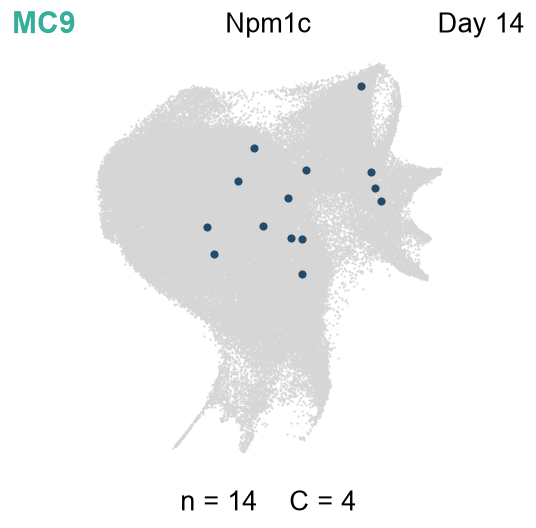

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_npm1c_d14.png


In [63]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='Npm1c';day='D14';stem='mc09_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · Npm1c · Day 27

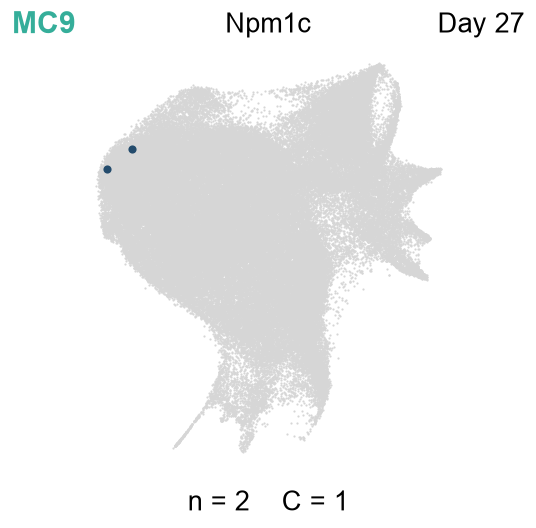

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_npm1c_d27.png


In [64]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='Npm1c';day='D27';stem='mc09_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · Dnmt3a · Day 14

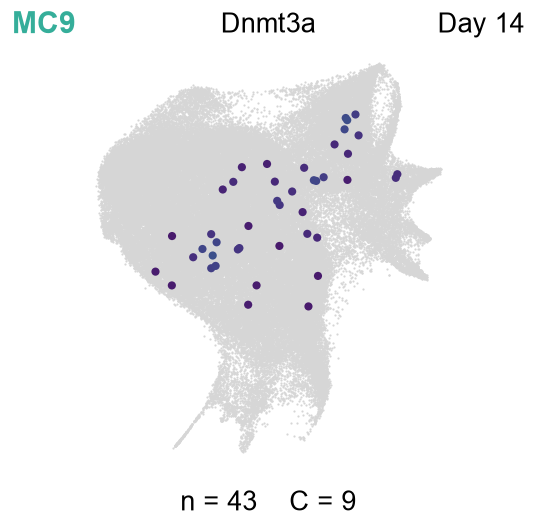

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_dnmt3a_d14.png


In [65]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='Dnmt3a';day='D14';stem='mc09_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC9 · Dnmt3a · Day 27

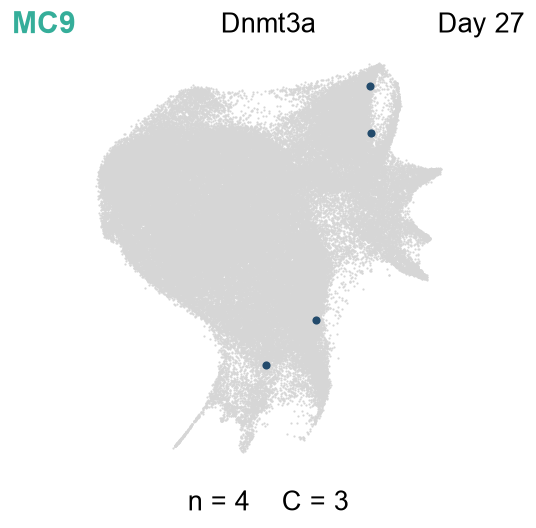

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc09_dnmt3a_d27.png


In [66]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=9;arm='Dnmt3a';day='D27';stem='mc09_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · WT · Day 7

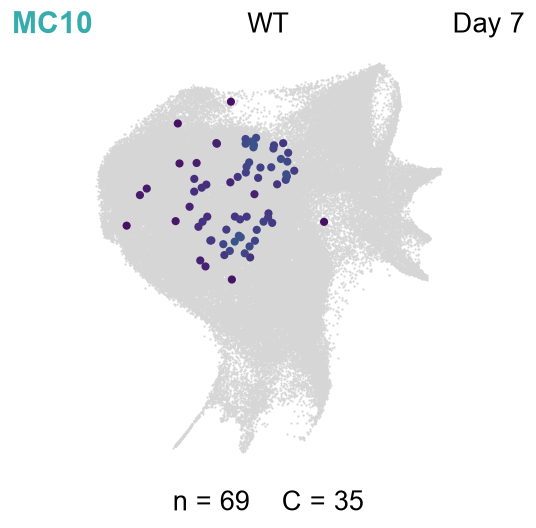

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d7.png


In [67]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='WT';day='D7';stem='mc10_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · WT · Day 14

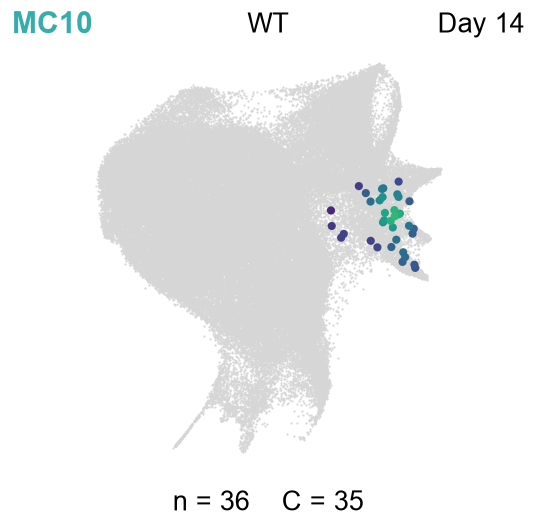

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d14.png


In [68]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='WT';day='D14';stem='mc10_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · WT · Day 27

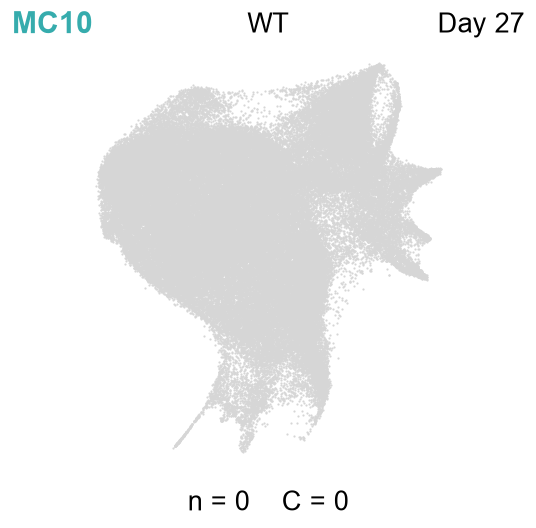

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_wt_d27.png


In [69]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='WT';day='D27';stem='mc10_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · Npm1c · Day 14

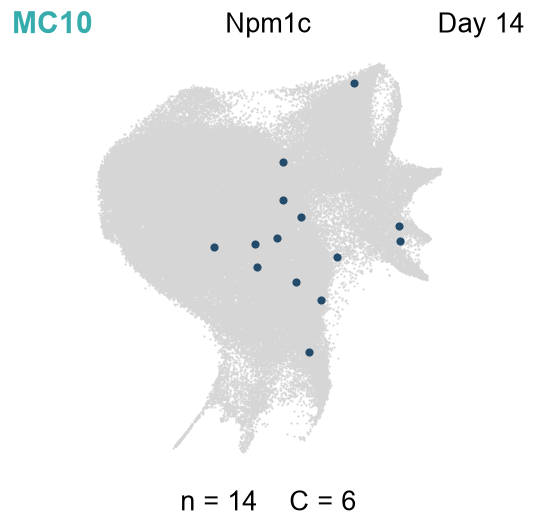

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_npm1c_d14.png


In [70]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='Npm1c';day='D14';stem='mc10_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · Npm1c · Day 27

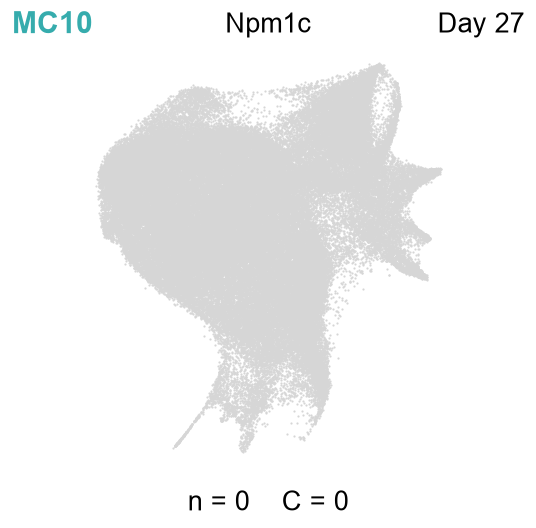

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_npm1c_d27.png


In [71]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='Npm1c';day='D27';stem='mc10_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · Dnmt3a · Day 14

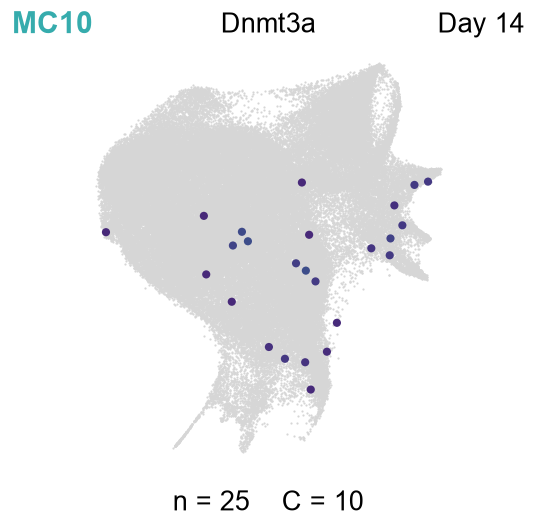

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_dnmt3a_d14.png


In [72]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='Dnmt3a';day='D14';stem='mc10_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC10 · Dnmt3a · Day 27

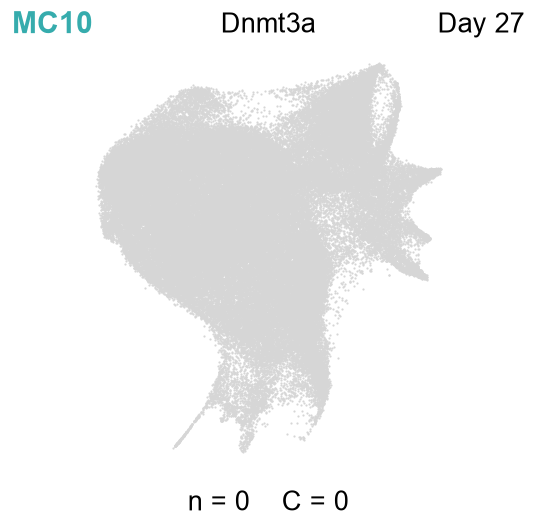

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc10_dnmt3a_d27.png


In [73]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=10;arm='Dnmt3a';day='D27';stem='mc10_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · WT · Day 7

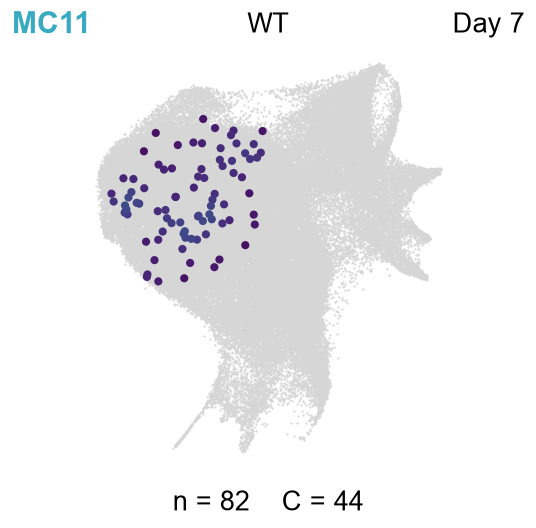

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d7.png


In [74]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='WT';day='D7';stem='mc11_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · WT · Day 14

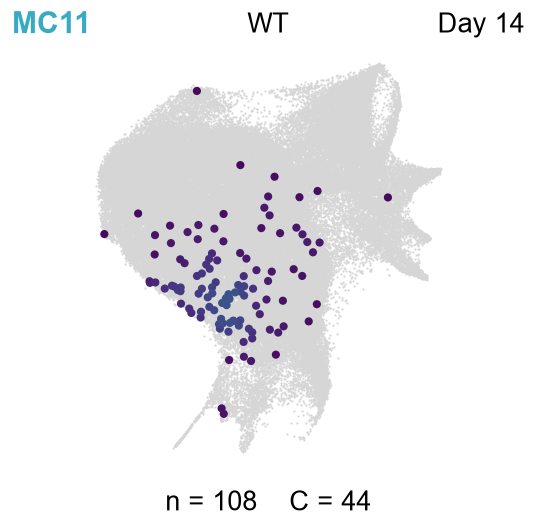

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d14.png


In [75]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='WT';day='D14';stem='mc11_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · WT · Day 27

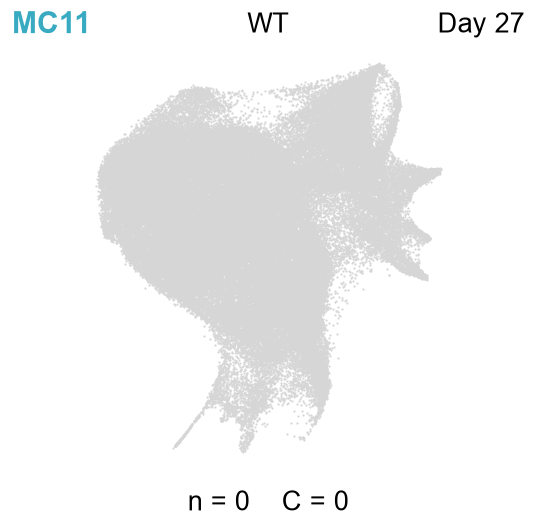

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_wt_d27.png


In [76]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='WT';day='D27';stem='mc11_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · Npm1c · Day 14

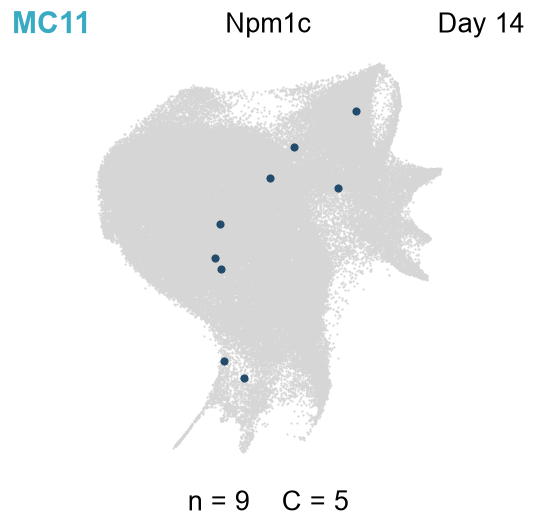

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_npm1c_d14.png


In [77]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='Npm1c';day='D14';stem='mc11_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · Npm1c · Day 27

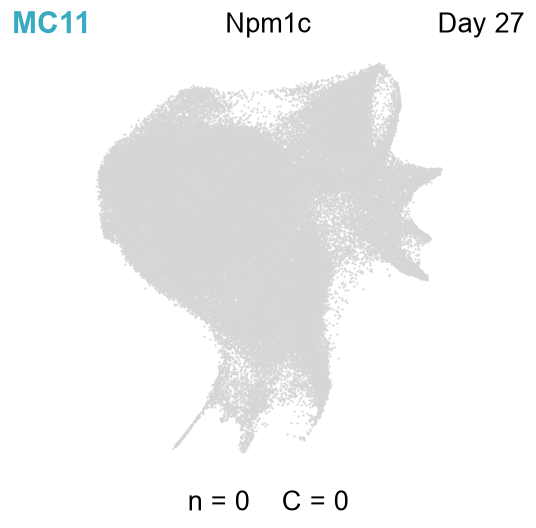

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_npm1c_d27.png


In [78]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='Npm1c';day='D27';stem='mc11_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · Dnmt3a · Day 14

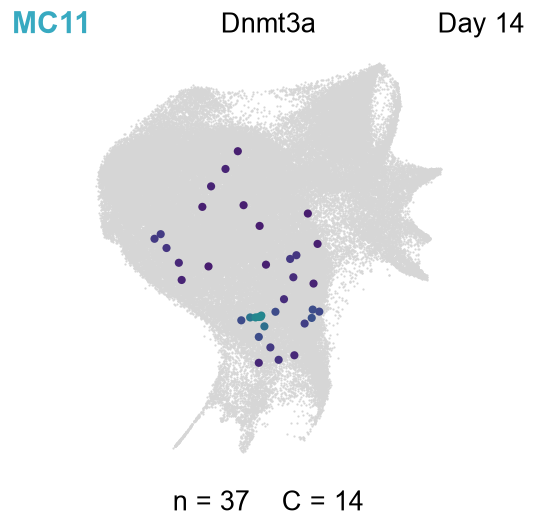

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_dnmt3a_d14.png


In [79]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='Dnmt3a';day='D14';stem='mc11_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC11 · Dnmt3a · Day 27

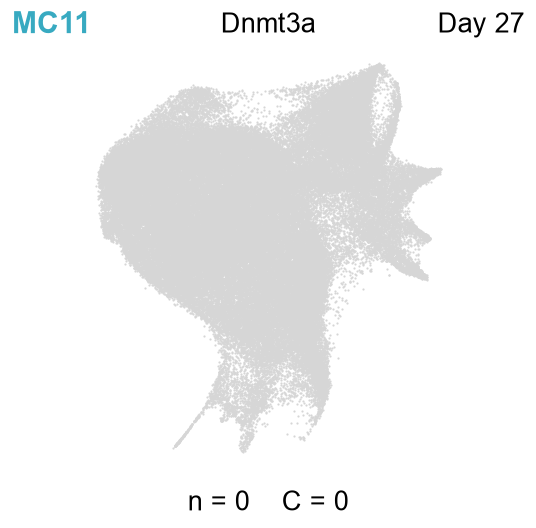

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc11_dnmt3a_d27.png


In [80]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=11;arm='Dnmt3a';day='D27';stem='mc11_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · WT · Day 7

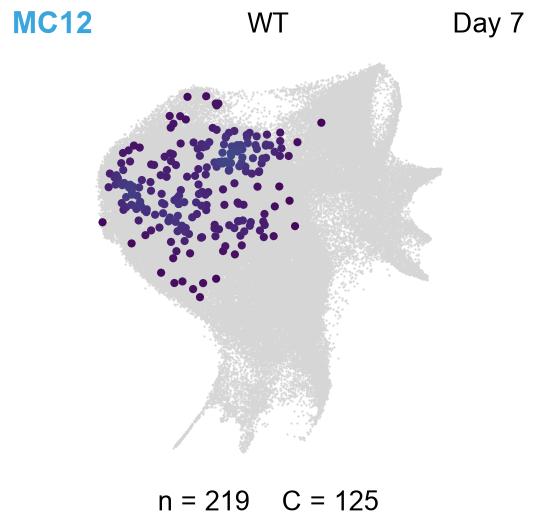

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d7.png


In [81]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='WT';day='D7';stem='mc12_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · WT · Day 14

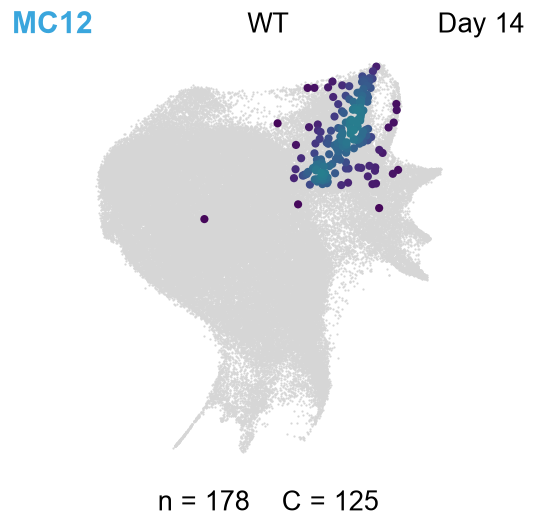

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d14.png


In [82]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='WT';day='D14';stem='mc12_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · WT · Day 27

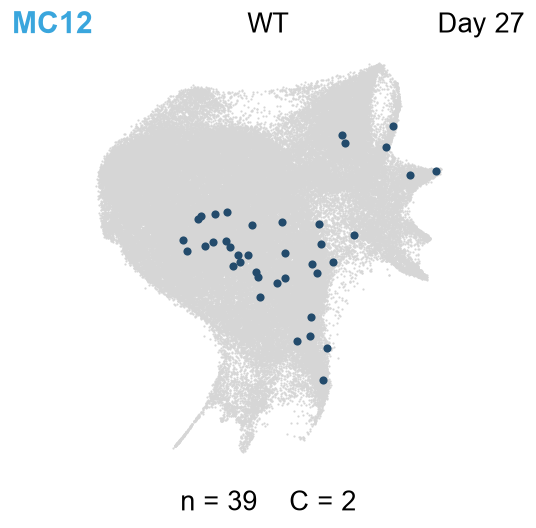

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_wt_d27.png


In [83]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='WT';day='D27';stem='mc12_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · Npm1c · Day 14

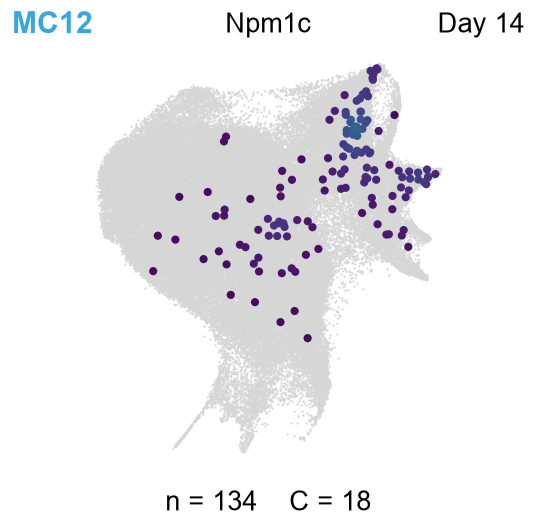

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_npm1c_d14.png


In [84]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='Npm1c';day='D14';stem='mc12_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · Npm1c · Day 27

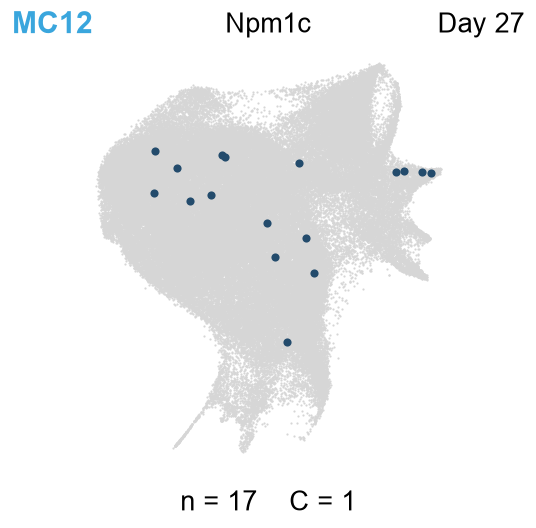

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_npm1c_d27.png


In [85]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='Npm1c';day='D27';stem='mc12_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · Dnmt3a · Day 14

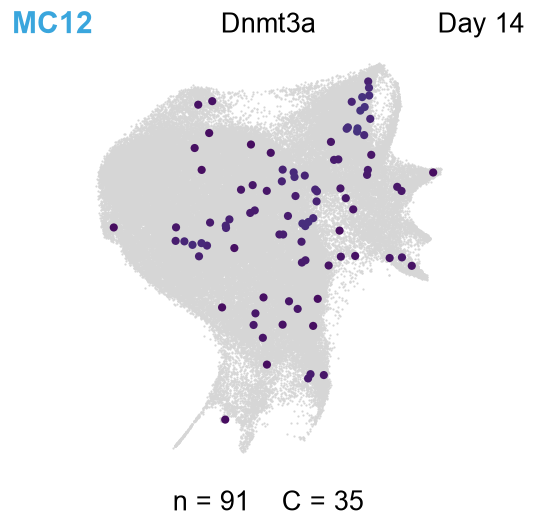

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_dnmt3a_d14.png


In [86]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='Dnmt3a';day='D14';stem='mc12_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC12 · Dnmt3a · Day 27

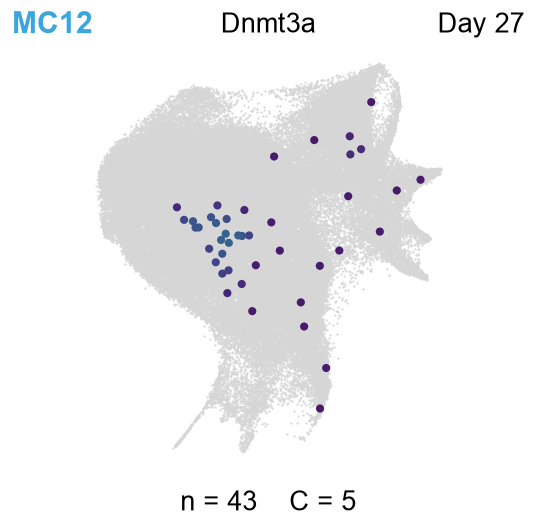

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc12_dnmt3a_d27.png


In [87]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=12;arm='Dnmt3a';day='D27';stem='mc12_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · WT · Day 7

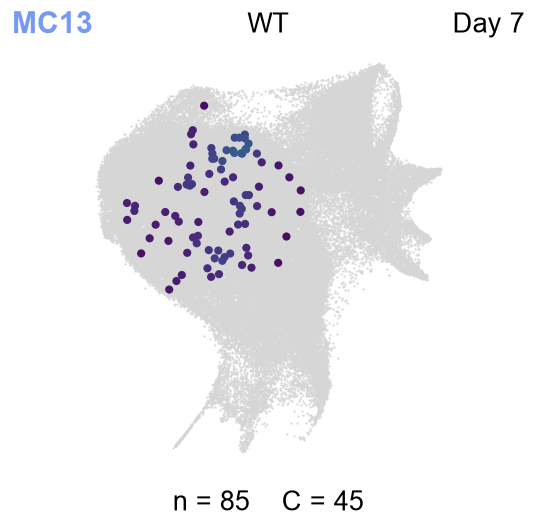

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d7.png


In [88]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='WT';day='D7';stem='mc13_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · WT · Day 14

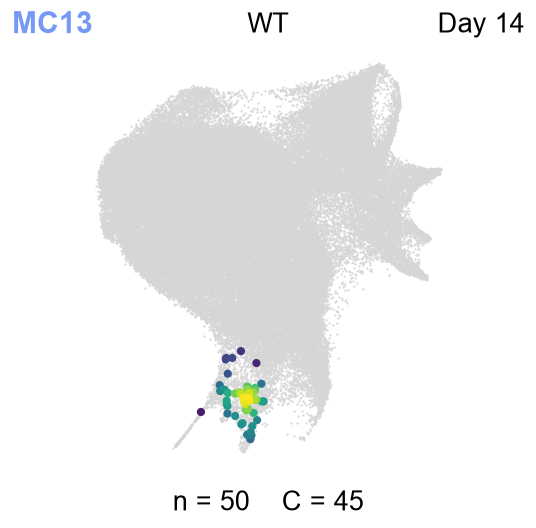

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d14.png


In [89]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='WT';day='D14';stem='mc13_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · WT · Day 27

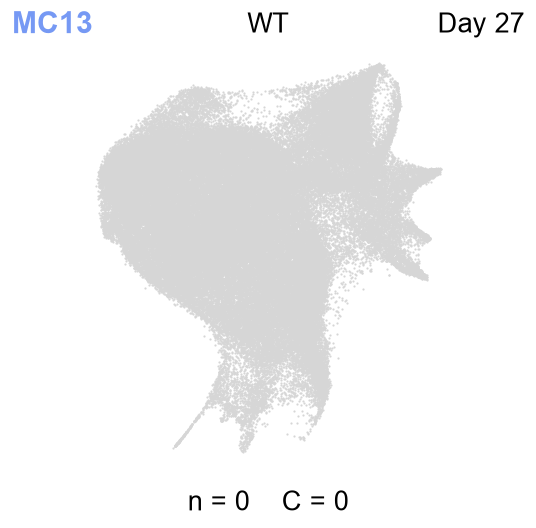

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_wt_d27.png


In [90]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='WT';day='D27';stem='mc13_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · Npm1c · Day 14

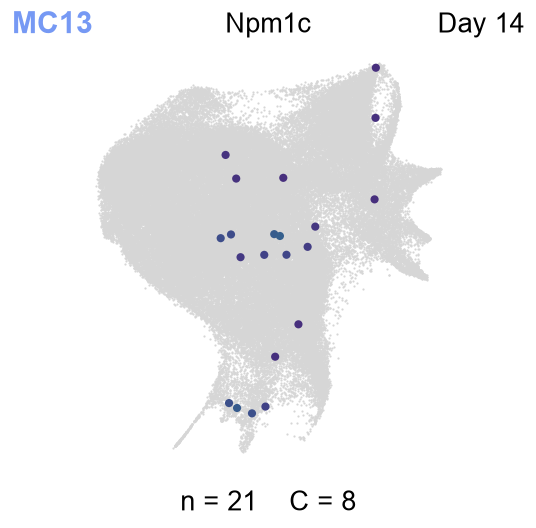

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_npm1c_d14.png


In [91]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='Npm1c';day='D14';stem='mc13_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · Npm1c · Day 27

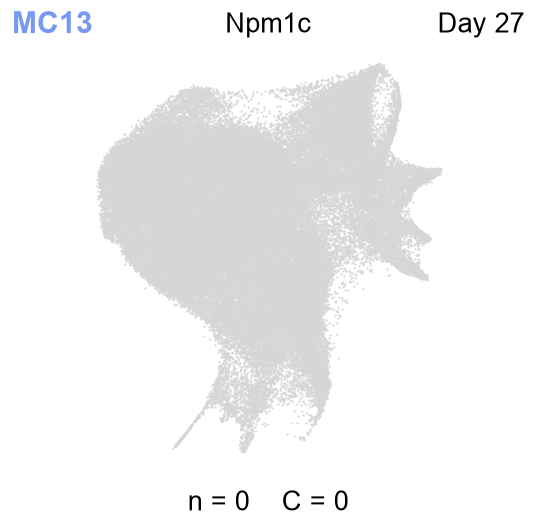

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_npm1c_d27.png


In [92]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='Npm1c';day='D27';stem='mc13_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · Dnmt3a · Day 14

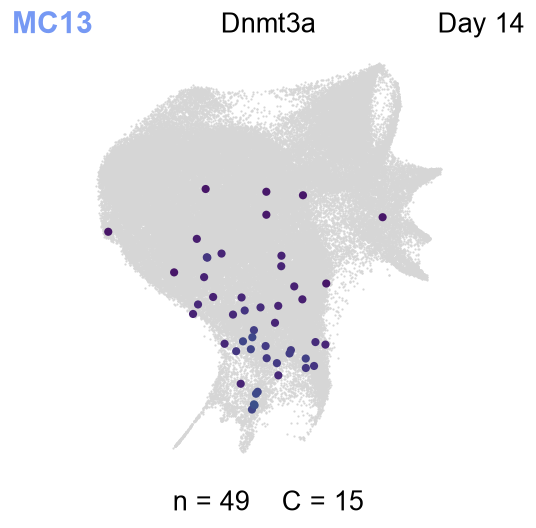

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_dnmt3a_d14.png


In [93]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='Dnmt3a';day='D14';stem='mc13_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC13 · Dnmt3a · Day 27

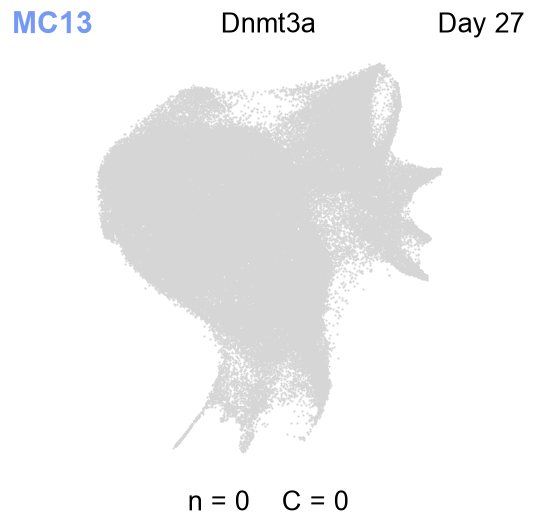

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc13_dnmt3a_d27.png


In [94]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=13;arm='Dnmt3a';day='D27';stem='mc13_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · WT · Day 7

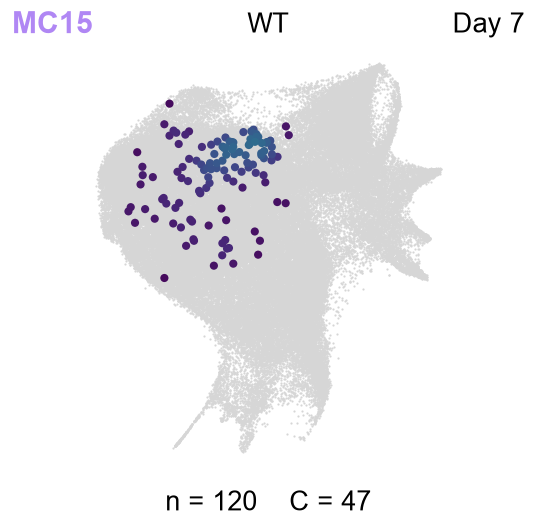

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d7.png


In [95]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='WT';day='D7';stem='mc15_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · WT · Day 14

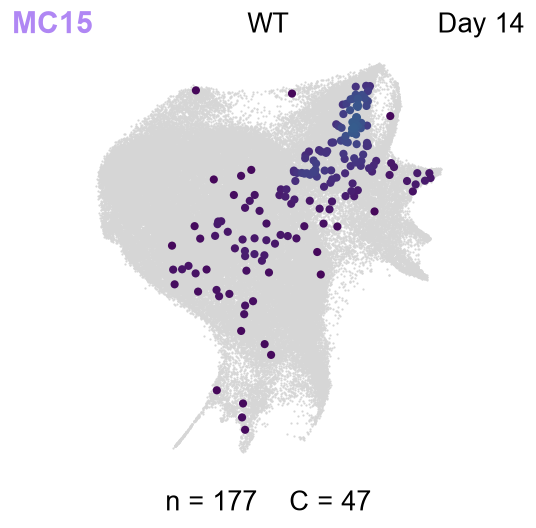

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d14.png


In [96]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='WT';day='D14';stem='mc15_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · WT · Day 27

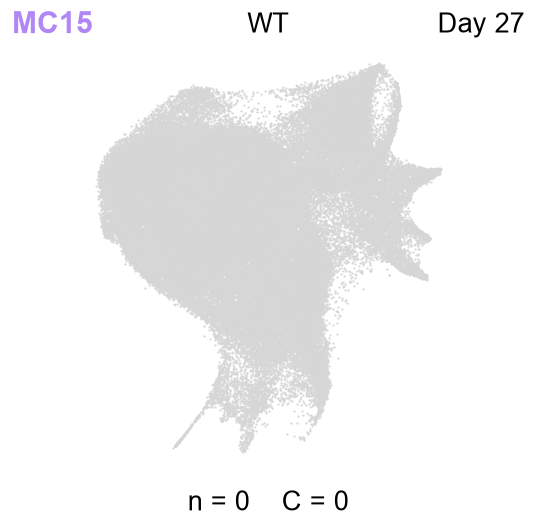

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_wt_d27.png


In [97]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='WT';day='D27';stem='mc15_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · Npm1c · Day 14

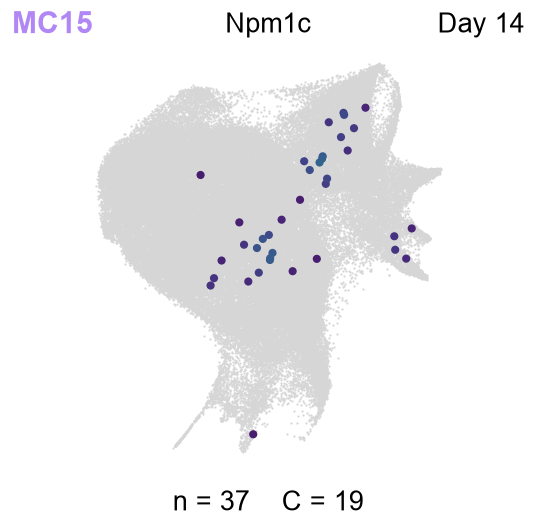

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_npm1c_d14.png


In [98]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='Npm1c';day='D14';stem='mc15_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · Npm1c · Day 27

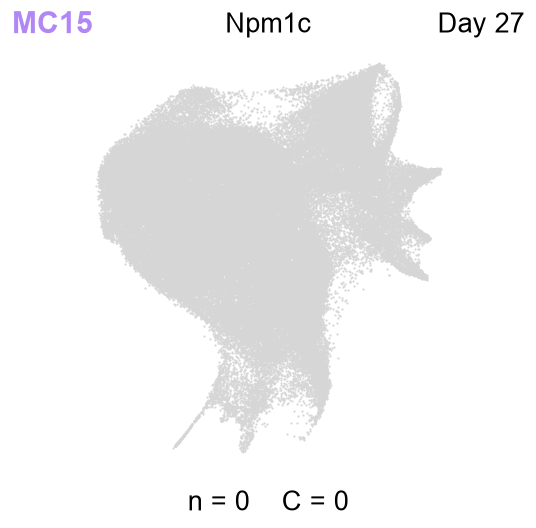

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_npm1c_d27.png


In [99]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='Npm1c';day='D27';stem='mc15_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · Dnmt3a · Day 14

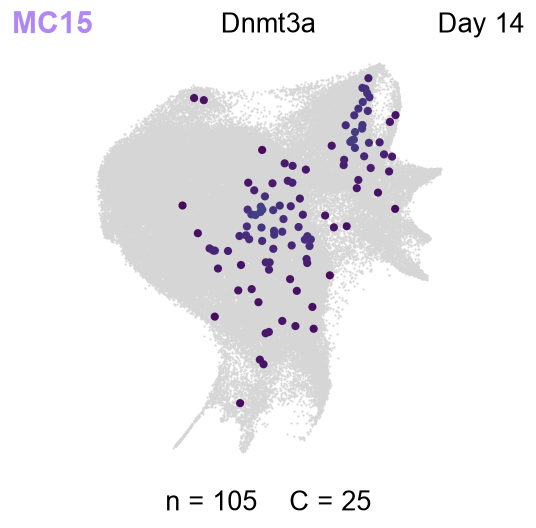

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_dnmt3a_d14.png


In [100]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='Dnmt3a';day='D14';stem='mc15_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC15 · Dnmt3a · Day 27

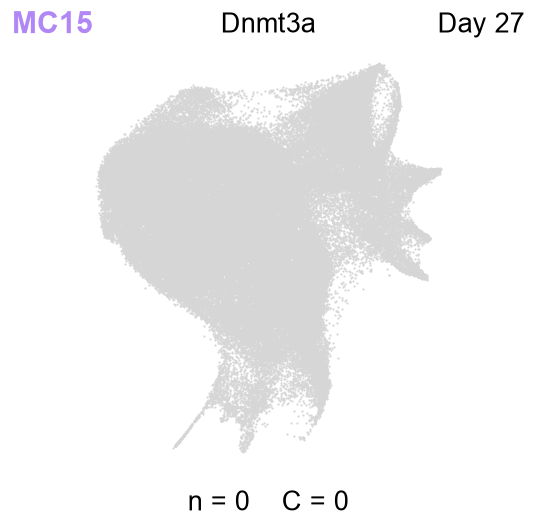

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc15_dnmt3a_d27.png


In [101]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=15;arm='Dnmt3a';day='D27';stem='mc15_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · WT · Day 7

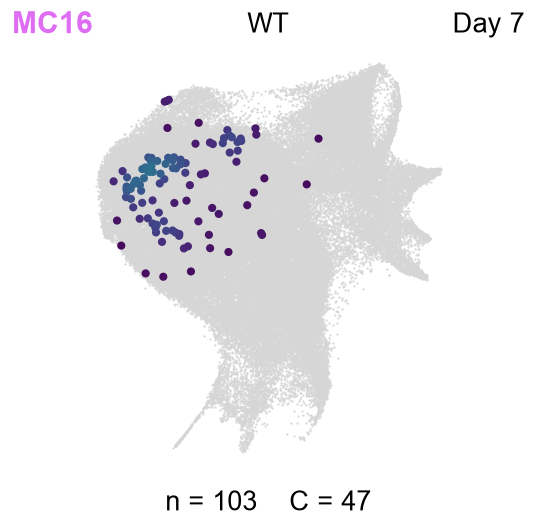

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d7.png


In [102]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='WT';day='D7';stem='mc16_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · WT · Day 14

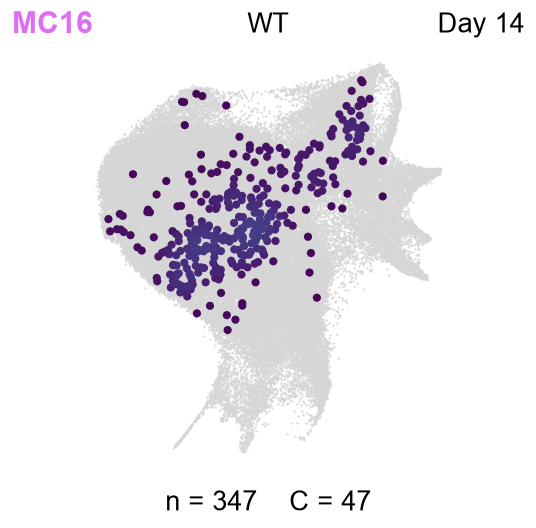

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d14.png


In [103]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='WT';day='D14';stem='mc16_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · WT · Day 27

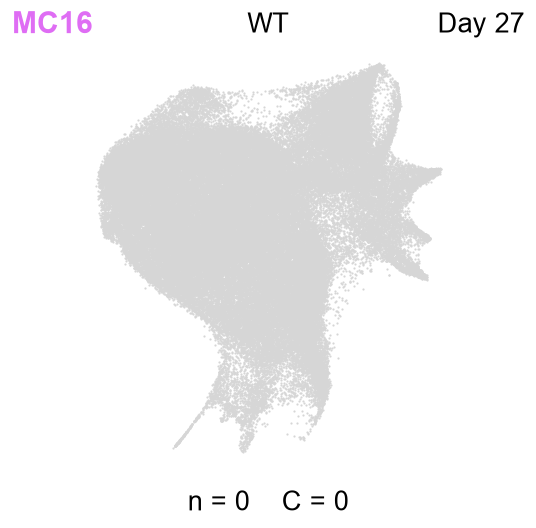

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_wt_d27.png


In [104]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='WT';day='D27';stem='mc16_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · Npm1c · Day 14

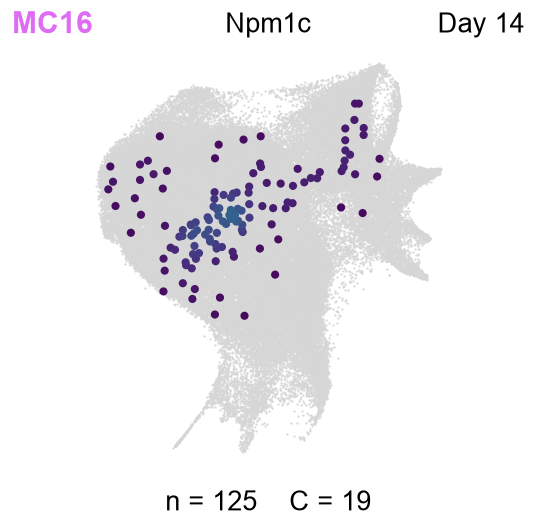

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_npm1c_d14.png


In [105]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='Npm1c';day='D14';stem='mc16_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · Npm1c · Day 27

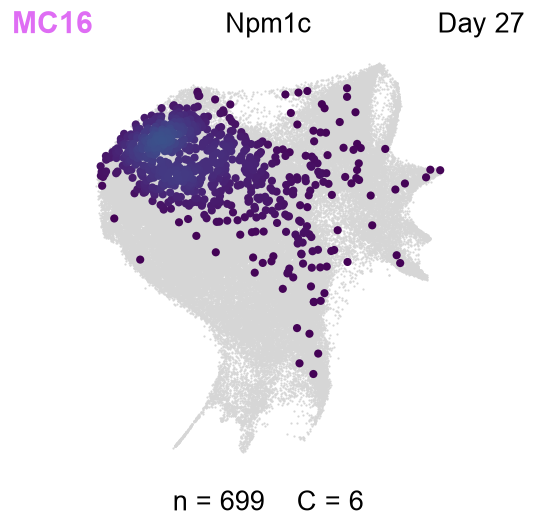

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_npm1c_d27.png


In [106]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='Npm1c';day='D27';stem='mc16_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · Dnmt3a · Day 14

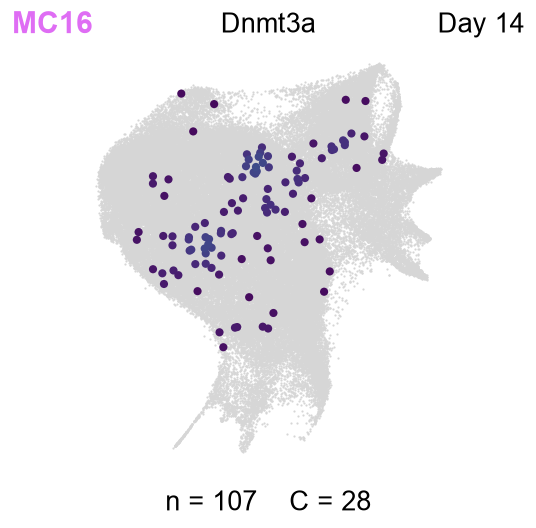

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_dnmt3a_d14.png


In [107]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='Dnmt3a';day='D14';stem='mc16_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC16 · Dnmt3a · Day 27

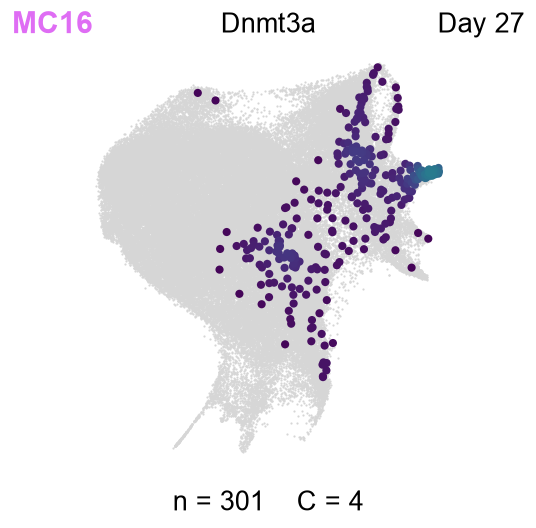

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc16_dnmt3a_d27.png


In [108]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=16;arm='Dnmt3a';day='D27';stem='mc16_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · WT · Day 7

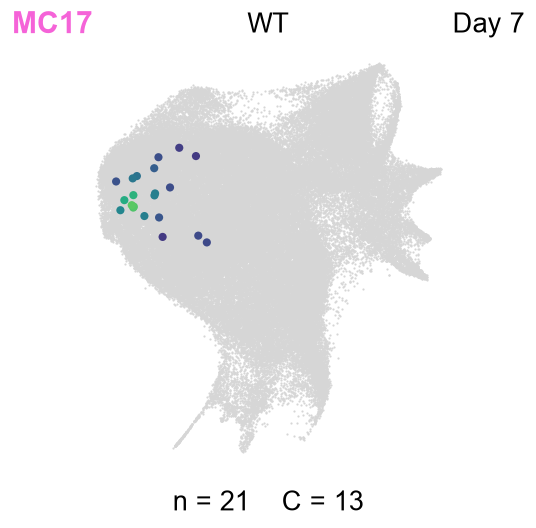

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d7.png


In [109]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='WT';day='D7';stem='mc17_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · WT · Day 14

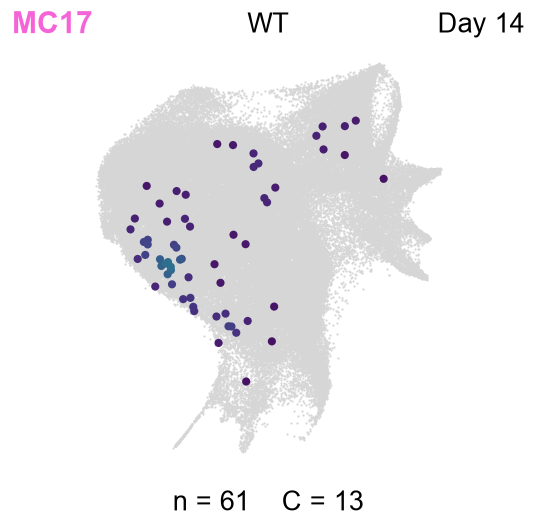

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d14.png


In [110]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='WT';day='D14';stem='mc17_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · WT · Day 27

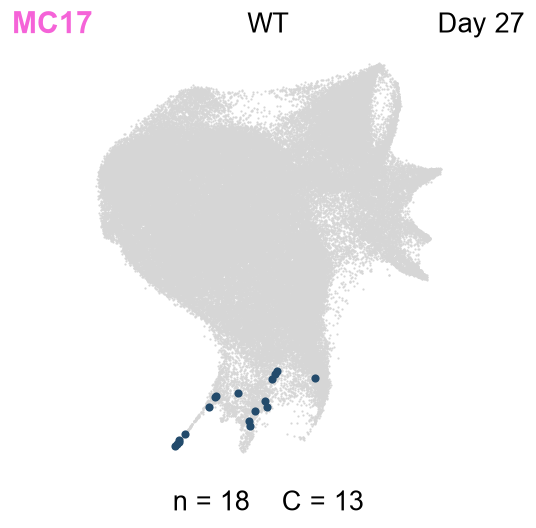

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_wt_d27.png


In [111]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='WT';day='D27';stem='mc17_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · Npm1c · Day 14

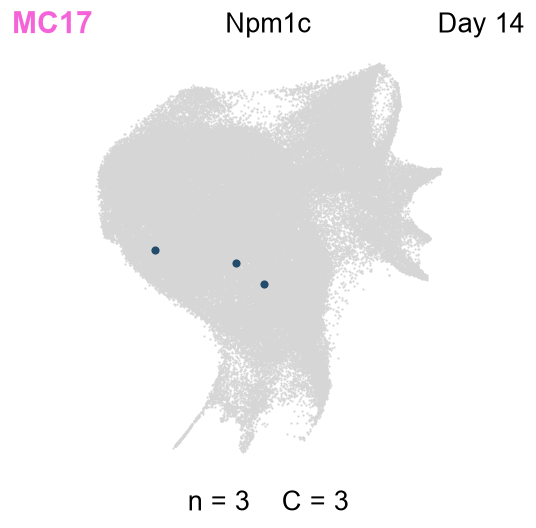

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_npm1c_d14.png


In [112]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='Npm1c';day='D14';stem='mc17_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · Npm1c · Day 27

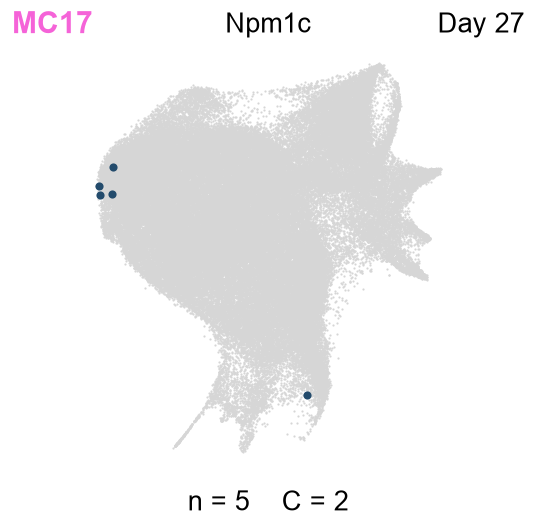

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_npm1c_d27.png


In [113]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='Npm1c';day='D27';stem='mc17_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · Dnmt3a · Day 14

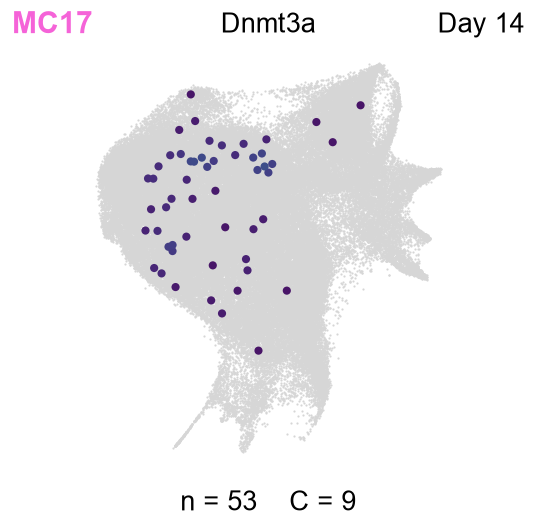

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_dnmt3a_d14.png


In [114]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='Dnmt3a';day='D14';stem='mc17_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC17 · Dnmt3a · Day 27

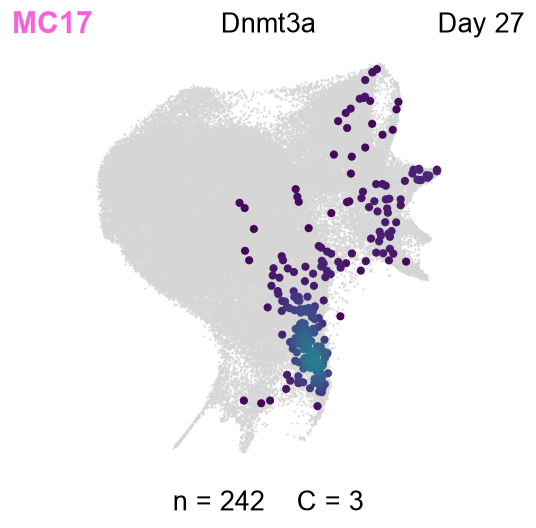

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc17_dnmt3a_d27.png


In [115]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=17;arm='Dnmt3a';day='D27';stem='mc17_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · WT · Day 7

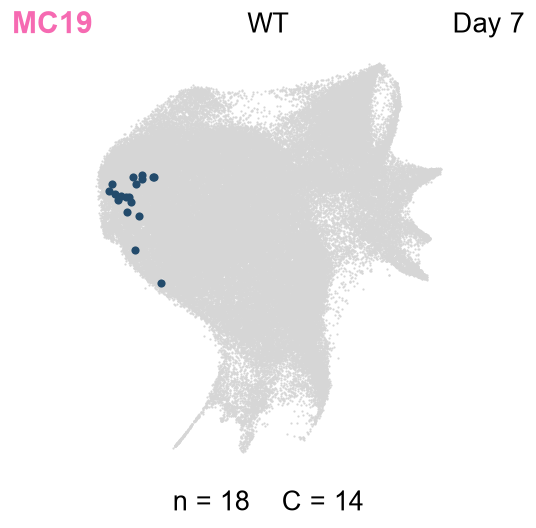

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d7.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d7.png


In [116]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='WT';day='D7';stem='mc19_wt_d7'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · WT · Day 14

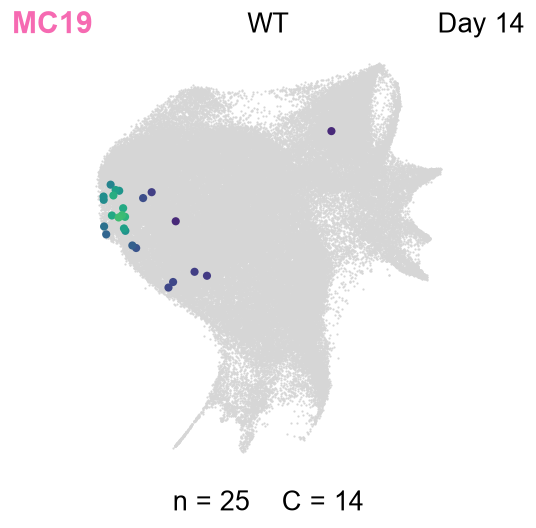

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d14.png


In [117]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='WT';day='D14';stem='mc19_wt_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · WT · Day 27

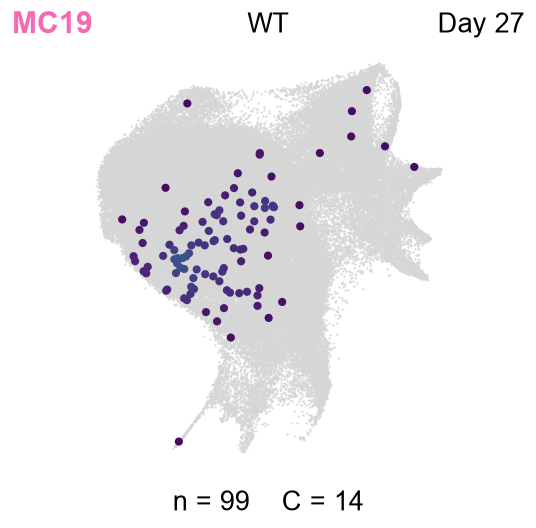

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_wt_d27.png


In [118]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='WT';day='D27';stem='mc19_wt_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · Npm1c · Day 14

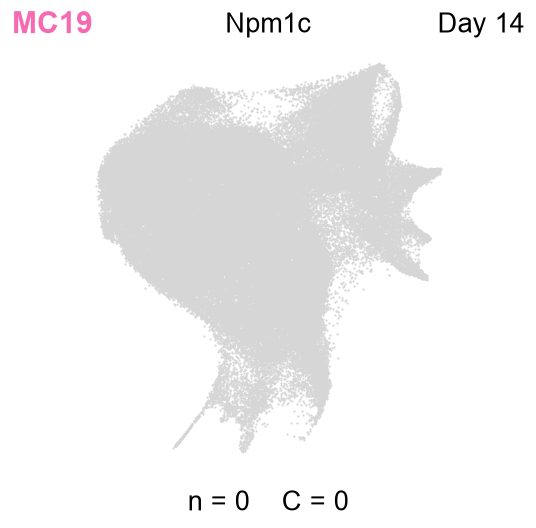

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_npm1c_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_npm1c_d14.png


In [119]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='Npm1c';day='D14';stem='mc19_npm1c_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · Npm1c · Day 27

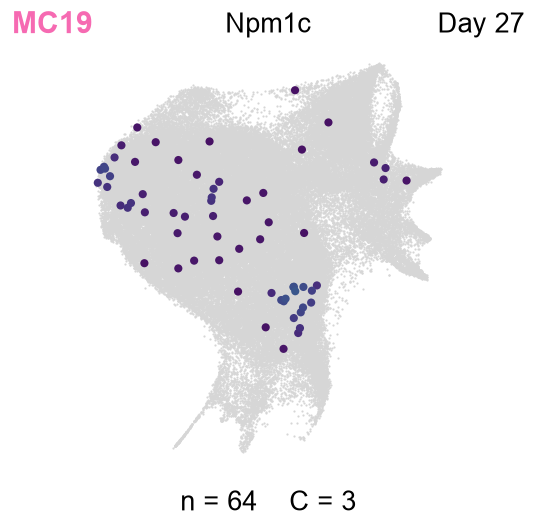

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_npm1c_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_npm1c_d27.png


In [120]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='Npm1c';day='D27';stem='mc19_npm1c_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · Dnmt3a · Day 14

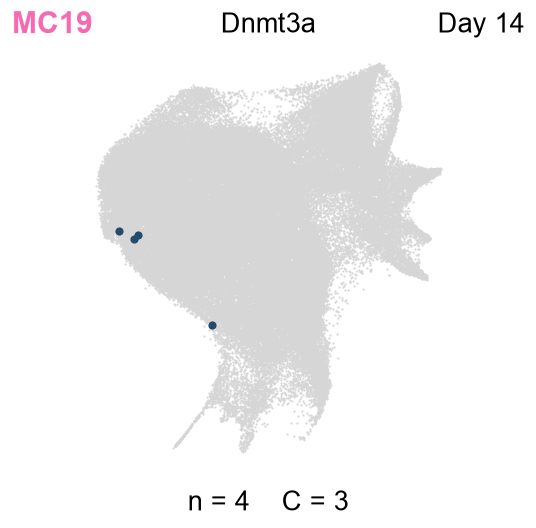

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_dnmt3a_d14.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_dnmt3a_d14.png


In [121]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='Dnmt3a';day='D14';stem='mc19_dnmt3a_d14'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### MC19 · Dnmt3a · Day 27

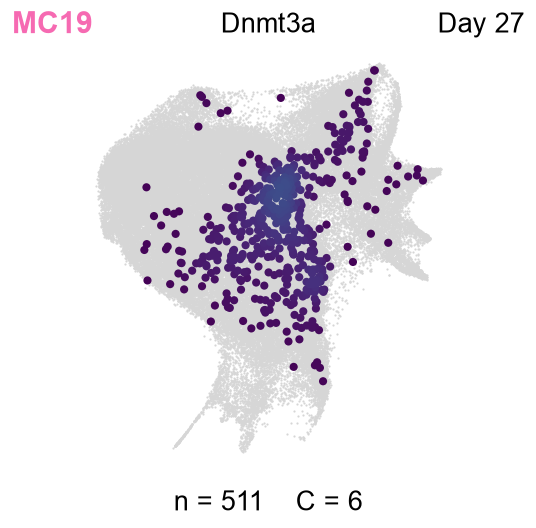

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_dnmt3a_d27.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/mc19_dnmt3a_d27.png


In [122]:

# One individual raw atlas map: full filtering, density shaping and construction remain visible here.
mc=19;arm='Dnmt3a';day='D27';stem='mc19_dnmt3a_d27'
selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
n=len(selected);family_count=selected.clone.nunique()
density_eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
if density_eligible:
    histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
    density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
    assert np.isfinite(density).all() and abs(density.sum()*DX*DY-1)<0.003
    point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
    assert (point_density>=0).all() and point_density.max()<=DENSITY_MAX*(1+1e-12)
    point_order=np.argsort(point_density,kind='stable')
    representation='density_colored_points'
else:
    point_order=np.arange(n);point_density=None
    representation='raw_points_sparse' if n else 'empty'
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,4.5),dpi=120)
ax=fig.add_axes([0.04,0.12,0.92,0.76])
ax.scatter(full_umap[:,0],full_umap[:,1],s=1.7,c='#D6D6D6',linewidths=0,alpha=1,rasterized=True)
if n:
    if density_eligible:
        ax.scatter(selected.umap1.to_numpy()[point_order],selected.umap2.to_numpy()[point_order],s=24,
                   c=point_density[point_order],cmap='viridis',norm=DENSITY_NORM,linewidths=0,alpha=1,rasterized=False)
    else:
        ax.scatter(selected.umap1,selected.umap2,s=24,c=SPARSE_COLOR,linewidths=0,alpha=1,rasterized=False)
ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
fig.text(0.055,0.93,f'MC{mc}',fontsize=18,fontweight='bold',color=MC_LABEL_COLORS[mc],ha='left',va='center')
fig.text(0.50,0.93,arm,fontsize=16,ha='center',va='center')
fig.text(0.945,0.93,f'Day {day[1:]}',fontsize=16,ha='right',va='center')
fig.text(0.50,0.045,f'n = {n:,}    C = {family_count:,}',fontsize=16,ha='center',va='center')
fig.canvas.draw()
for label in fig.texts:
    bounds=label.get_window_extent(fig.canvas.get_renderer())
    assert bounds.x0>=0 and bounds.y0>=0 and bounds.x1<=fig.bbox.width and bounds.y1<=fig.bbox.height
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig)
plt.close(fig)
render_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,'representation':representation,
                       'svg':str(svg_path.relative_to(OUT)),'png':str(png_path.relative_to(OUT)),
                       'svg_sha256':sha256(svg_path),'png_sha256':sha256(png_path),
                       'single_new_figure':True,'label_bounds_passed':True})
print(str(svg_path));print(str(png_path))


### Shared relative-density scale

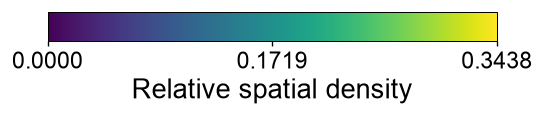

/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/atlas_relative_density_key.svg
/path/to/ChronoClone/analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/panels/atlas_relative_density_key.png


In [123]:

# One integral scale key: uses the common locked map scale, without changing any MC data.
previous_figures=set(plt.get_fignums())
fig=plt.figure(figsize=(4.8,1.2),dpi=120)
key_ax=fig.add_axes([0.11,0.53,0.78,0.20])
colorbar=fig.colorbar(matplotlib.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=key_ax,orientation='horizontal')
colorbar.set_ticks(np.linspace(0,DENSITY_MAX,3))
colorbar.ax.tick_params(labelsize=14,length=3)
colorbar.set_label('Relative spatial density',fontsize=16,labelpad=3)
colorbar.outline.set_linewidth(0.6)
fig.canvas.draw()
assert set(plt.get_fignums())-previous_figures=={fig.number}
stem='atlas_relative_density_key'
svg_path=OUT/'panels'/f'{stem}.svg';png_path=OUT/'panels'/f'{stem}.png'
fig.savefig(svg_path,dpi=180);fig.savefig(png_path,dpi=180)
display(fig);plt.close(fig)
print(str(svg_path));print(str(png_path))


In [124]:

# Complete atlas output and source checks. This cell emits no figures.
import xml.etree.ElementTree as ET
render_table=pd.DataFrame(render_records)
assert len(render_table)==119 and render_table.stem.is_unique
assert set(zip(render_table.mc,render_table.arm,render_table.day))==set(zip(scale_table.mc,scale_table.arm,scale_table.day))
reconciled=render_table.merge(scale_table,on=['mc','arm','day'],suffixes=('_render','_source'),validate='one_to_one')
for field in ['cells','families','representation']:assert reconciled[f'{field}_render'].equals(reconciled[f'{field}_source'])
assert render_table.single_new_figure.all() and render_table.label_bounds_passed.all()
for record in render_records:
    assert sha256(OUT/record['svg'])==record['svg_sha256'] and sha256(OUT/record['png'])==record['png_sha256']
    xml=ET.parse(OUT/record['svg'])
    text_elements=xml.findall('.//{http://www.w3.org/2000/svg}text')
    assert len(text_elements)>=4
    assert len(xml.findall('.//{http://www.w3.org/2000/svg}image'))==1
render_table.to_csv(OUT/'tables/atlas_panel_manifest.csv',index=False)
qc={'maps':len(render_table),'additional_scale_keys':1,'expected_maps':119,'all_sources_unchanged':all(sha256(ROOT/r.source)==r.sha256 for r in source_manifest.itertuples()),
    'all_counts_reconcile':True,'all_map_source_coordinates_exact':True,'single_figure_per_map_cell':True,
    'all_svg_labels_editable':True,'svg_background_only_rasterized':True,'all_panel_label_bounds_passed':True,
    'empty_panels':render_table.loc[render_table.cells.eq(0),'stem'].tolist(),
    'sparse_raw_point_panels':render_table.loc[render_table.representation.eq('raw_points_sparse'),'stem'].tolist(),
    'visual_inspection':'Pending separate individual PNG inspection; not implied by these mechanical checks.',
    'environment':environment}
assert qc['all_sources_unchanged']
(OUT/'reports/atlas_integrity.json').write_text(json.dumps(qc,indent=2))
display(qc)
display(render_table)


{'maps': 119,
 'additional_scale_keys': 1,
 'expected_maps': 119,
 'all_sources_unchanged': True,
 'all_counts_reconcile': True,
 'all_map_source_coordinates_exact': True,
 'single_figure_per_map_cell': True,
 'all_svg_labels_editable': True,
 'svg_background_only_rasterized': True,
 'all_panel_label_bounds_passed': True,
 'empty_panels': ['mc00_wt_d27',
  'mc02_wt_d27',
  'mc02_npm1c_d27',
  'mc02_dnmt3a_d27',
  'mc04_wt_d27',
  'mc05_wt_d27',
  'mc05_npm1c_d27',
  'mc05_dnmt3a_d27',
  'mc06_wt_d27',
  'mc09_wt_d27',
  'mc10_wt_d27',
  'mc10_npm1c_d27',
  'mc10_dnmt3a_d27',
  'mc11_wt_d27',
  'mc11_npm1c_d27',
  'mc11_dnmt3a_d27',
  'mc13_wt_d27',
  'mc13_npm1c_d27',
  'mc13_dnmt3a_d27',
  'mc15_wt_d27',
  'mc15_npm1c_d27',
  'mc15_dnmt3a_d27',
  'mc16_wt_d27',
  'mc19_npm1c_d14'],
 'sparse_raw_point_panels': ['mc01_wt_d27',
  'mc01_dnmt3a_d27',
  'mc02_npm1c_d14',
  'mc04_npm1c_d14',
  'mc04_npm1c_d27',
  'mc04_dnmt3a_d27',
  'mc05_npm1c_d14',
  'mc06_npm1c_d27',
  'mc06_dnmt3a_d27',

,stem,mc,arm,day,cells,families,representation,svg,png,svg_sha256,png_sha256,single_new_figure,label_bounds_passed
0,mc00_wt_d7,0,WT,D7,935,596,density_colored_points,panels/mc00_wt_d7.svg,panels/mc00_wt_d7.png,af3a09d4349f8d5fdd0e8ebfb5539091294c07e01c4e4e...,59c11f1ea1e8a0eee926db102b93e6e33a99f1c5fd6fcf...,True,True
1,mc00_wt_d14,0,WT,D14,1039,593,density_colored_points,panels/mc00_wt_d14.svg,panels/mc00_wt_d14.png,299cb22d22c8e8b7558905566f7f04eabaadd388346197...,82fd6dc1b302766167c8bacd1f0565c068732aacdcb4d1...,True,True
2,mc00_wt_d27,0,WT,D27,0,0,empty,panels/mc00_wt_d27.svg,panels/mc00_wt_d27.png,b46bb06baec15a92df7a490c29a7327df04fef53761016...,79a0f3b23fa8d3531c6ed8d468b01307569a80576b2830...,True,True
3,mc00_npm1c_d14,0,Npm1c,D14,218,90,density_colored_points,panels/mc00_npm1c_d14.svg,panels/mc00_npm1c_d14.png,ce618d80b196c16a733d70cfdf5c45d0d5f5c49a536823...,a56199f5d6304ae5a28d8f3333f313129e17de5a9e3142...,True,True
4,mc00_npm1c_d27,0,Npm1c,D27,589,26,density_colored_points,panels/mc00_npm1c_d27.svg,panels/mc00_npm1c_d27.png,dff365b12597623de8648dd747f2357c1525c87f4994ab...,fbb159ead84b438576773a740e7f296553d4282f39dbbb...,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,mc19_wt_d27,19,WT,D27,99,14,density_colored_points,panels/mc19_wt_d27.svg,panels/mc19_wt_d27.png,2204c6e1e28b7b0e704d7ddd386f343112b96b060d19ea...,1cb503c45dc15a50e1a45c796a78f69798a642d8c36bee...,True,True
115,mc19_npm1c_d14,19,Npm1c,D14,0,0,empty,panels/mc19_npm1c_d14.svg,panels/mc19_npm1c_d14.png,1584cc00bc90418c4eb4d10cd1e33cb9568f563a8e6ab2...,feca2ed401a52f081019e0e3bb35038d68ab26bf2c142d...,True,True
116,mc19_npm1c_d27,19,Npm1c,D27,64,3,density_colored_points,panels/mc19_npm1c_d27.svg,panels/mc19_npm1c_d27.png,1a3a20782a5ce2998c3e5044e7e7cb23121f4885286aee...,fc9b16a1d255c94b902463459797c47f381aaba5531640...,True,True
117,mc19_dnmt3a_d14,19,Dnmt3a,D14,4,3,raw_points_sparse,panels/mc19_dnmt3a_d14.svg,panels/mc19_dnmt3a_d14.png,f5bca869d1fca9b9087e2c70f4f8c01c0b3de530c79f79...,3acf595f7652c6ac7d94dc8f9cf9f7ac3611ebde796819...,True,True
